# Imports

In [1]:
import numpyro
numpyro.set_host_device_count(4)

import jax
import jax.numpy as jnp
print("JAX:", jax.__version__)
print("local device count:", jax.local_device_count())
print("local devices:")
for d in jax.local_devices():
    print("  ", d)
    
import numpyro.distributions as dist
from numpyro.infer import MCMC, NUTS

from likelihood import (
    FD_gaussian_likelihood,
    FD_marg_fullnormal_gaussianlikelihood,
    draw_fluences_fullnormal_gaussmarg,
    FD_marg_halfnormal_nooverlap_gaussianlikelihood,
    draw_fluences_halfnormal_nooverlap_gaussmarg,
)
from model import setup_model

import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import arviz as az
import arviz_plots as azp
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker

import random

JAX: 0.11.2
local device count: 4
local devices:
   cpu:0
   cpu:1
   cpu:2
   cpu:3


In [2]:
# import sys
# print(sys.executable)  # Should point to your venv path, not /mnt/sw/nix/...

In [3]:
# import tqdm.std

# # Force tqdm to use newlines and flush output instantly for Jupyter
# def line_printer(file):
#     def print_status(s):
#         file.write(s.replace("\r", "") + "\n")
#         file.flush()
#     return print_status

# tqdm.std.status_printer = line_printer

In [4]:
# import sys
# import tqdm.std

# class ThreadSafeStdOut:
#     def __init__(self, stream):
#         self.stream = stream
#     def write(self, s):
#         self.stream.write(s)
#         self.stream.flush()
#     def flush(self):
#         self.stream.flush()

# # Override tqdm's default output file handle
# tqdm.std.tqdm.stqdm_file = ThreadSafeStdOut(sys.stdout)

## Real data

#### Pulling the data

In [134]:
data = jnp.load('/mnt/home/hsiegel/FRBayes/data/event_22154974_BB.npz')
power, freq, time = data['power'], data['freq'], data['time']
freq = freq[::-1]
power = power[::-1, :]

# -------------------------------------------------------------------
# Frequency downsampling: average consecutive blocks of n_avg good channels.
# Blocks are formed from good channels after bad are thrown out, so every block contains exactly n_avg
# of them and the Gaussian approximation to the chi'^2 statistics is uniform across blocks
# (m -> n_avg * m). Blocks straddling masked regions therefore span a wider range of real
# frequency than n_avg contiguous channels; `freq_span` reports that, and the residual
# dispersion-smearing bias it causes is small and is corrected by the likelihood reweighting.
# some small number of channels may be dropped from the top of the band if they aren't in a full block of n_avg.
# -------------------------------------------------------------------
n_avg = 8

n_chan = freq.shape[0]
n_blocks = n_chan // n_avg
n_dropped = n_chan - n_blocks * n_avg   # trailing channels, dropped to keep m uniform

freq_blocks = freq[: n_blocks * n_avg].reshape(n_blocks, n_avg)
power_blocks = power[: n_blocks * n_avg].reshape(n_blocks, n_avg, -1)

freq = freq_blocks.mean(axis=1)          # block centre = mean of its members' frequencies
power = power_blocks.mean(axis=1)
freq_span = freq_blocks.max(axis=1) - freq_blocks.min(axis=1)

print(f"{n_chan} good channels -> {n_blocks} blocks of {n_avg} ({n_dropped} dropped); "
      f"block span median {float(jnp.median(freq_span)):.3f} MHz, max {float(freq_span.max()):.3f} MHz")

# Shift to relative time starting at t = 0 (prevents float32 phase rounding)
time_rel = jnp.asarray(time - time[0], dtype=jnp.float32)
freq_channels = jnp.asarray(freq, dtype=jnp.float32)[:, None]
data_reshaped = jnp.asarray(power, dtype=jnp.float32)

Nseg = time_rel.shape[0]
dt = time_rel[1] - time_rel[0]

# Off-pulse noise region (first 20% of time bins)
n_noise_bins = Nseg // 5
noise_data = data_reshaped[:, :n_noise_bins]

# Off-pulse baseline median and MAD estimate of time-domain std dev (sigma_td)
noise_median_estimates = jnp.median(noise_data, axis=1, keepdims=True)
mad = jnp.median(jnp.abs(noise_data - noise_median_estimates), axis=1, keepdims=True)
sigma_estimates = mad * 1.4826  # Time-domain std dev (varsigma_a) per channel

# -------------------------------------------------------------------
# Per-channel weights for the orthogonal spectral basis.
# These are the squared on-pulse matched-filter SNR per channel, i.e. a measurement of where
# the burst actually carries signal-to-noise. They define the metric in which the spectral
# basis polynomials are orthogonalized; weighting every channel equally instead leaves the
# gamma-beta degeneracy largely intact, because the SED spans orders of magnitude across the
# band. The weights are fixed from the data before sampling, so the basis is a fixed change of
# coordinates, not a parameter-dependent one.
# -------------------------------------------------------------------

def estimate_channel_weights(data_td, sigma_td, on_slice=None, threshold=0.1, n_smooth=5):
    """
    w_a proportional to (on-pulse SNR in channel a)^2, normalized to sum to 1.

    data_td:  (nfreq, ntime), baseline-subtracted
    sigma_td: (nfreq, 1) per-channel time-domain noise std
    on_slice: burst window; if None, found from the noise-weighted profile by extending
              outward from the peak while it exceeds `threshold` times the peak
    n_smooth: channels to smooth the weights over, since the per-channel SNR is itself noisy

    Returns (weights, on_slice).
    """
    d = np.asarray(data_td)
    s = np.asarray(sigma_td).reshape(-1)

    # Masked / zero-noise channels get zero weight
    inv_sigma = np.where(np.isfinite(s) & (s > 0), 1.0 / np.maximum(s, np.finfo(float).tiny), 0.0)

    if on_slice is None:
        profile = (d * inv_sigma[:, None]).sum(axis=0)
        peak = int(np.argmax(profile))
        cut = threshold * profile[peak]
        lo = hi = peak
        while lo > 0 and profile[lo - 1] > cut:
            lo -= 1
        while hi < profile.size - 1 and profile[hi + 1] > cut:
            hi += 1
        on_slice = slice(lo, hi + 1)

    n_on = on_slice.stop - on_slice.start
    snr_per_channel = d[:, on_slice].sum(axis=1) * inv_sigma / np.sqrt(n_on)

    # Negative values are noise fluctuations in channels with no signal
    weights = np.maximum(snr_per_channel, 0.0) ** 2
    if n_smooth > 1:
        weights = np.convolve(weights, np.ones(n_smooth) / n_smooth, mode="same")

    return weights / weights.sum(), on_slice


def orthogonal_spectral_basis(freq, weights, freq_ref):
    """
    Gram-Schmidt orthogonalization of {1, x, x^2} in the weighted metric, x = ln(nu/nu_r),
    returning the two non-constant basis functions normalized to unit weighted RMS.

    Orthogonalizing against the constant decouples the spectral shape from the fluence, since
    a constant in ln F is exactly a rescaling of A. The returned coefficients convert the
    sampled c1, c2 back to the conventional gamma, beta:
        gamma = gamma_c1 * c1 + gamma_c2 * c2,   beta = beta_c2 * c2.
    """
    x = np.log(np.asarray(freq).reshape(-1) / freq_ref)
    w = np.asarray(weights).reshape(-1)
    ip = lambda u, v: np.sum(w * u * v)

    P0 = np.ones_like(x)
    P1 = x - ip(x, P0) / ip(P0, P0) * P0
    P2 = x ** 2 - ip(x ** 2, P0) / ip(P0, P0) * P0 - ip(x ** 2, P1) / ip(P1, P1) * P1

    # Unit weighted RMS, so the sampled coefficients are O(1)
    P1 /= np.sqrt(ip(P1, P1) / w.sum())
    P2 /= np.sqrt(ip(P2, P2) / w.sum())

    # P1, P2 are polynomials in x, so the map back to gamma, beta is exact
    a1, b1 = np.polyfit(x, P1, 1)
    a2, b2, d2 = np.polyfit(x, P2, 2)
    return P1, P2, dict(gamma_c1=a1, gamma_c2=b2, beta_c2=a2)


channel_weights, on_slice = estimate_channel_weights(data_reshaped, sigma_estimates)
P1, P2, spectral_coeff_map = orthogonal_spectral_basis(np.asarray(freq), channel_weights, freq_channels_ref)
print(f"on-pulse window {on_slice} ({on_slice.stop - on_slice.start} bins)")

# Baseline subtract off-pulse median
data_reshaped = data_reshaped - noise_median_estimates

# Fourier domain data (d_tilde = dt * rfft(d_td))
data_reshaped_FFT = dt * jnp.fft.rfft(data_reshaped, axis=-1)

# --- CRITICAL: Convert time-domain MAD std dev to Fourier-domain noise std dev ---
# sigma_noise = dt * sigma_td * sqrt(L / 2)
sigma_noise = dt * sigma_estimates * jnp.sqrt(Nseg / 2.0)

# Zero/NaN guard for masked RFI channels
sigma_noise = jnp.where(
    (sigma_noise <= jnp.float32(0.0)) | jnp.isnan(sigma_noise),
    jnp.inf,
    sigma_noise,
)

820 good channels -> 102 blocks of 8 (4 dropped); block span median 3.125 MHz, max 4.688 MHz


# Setup unmarginalized full normal likelihood, model and sampler

In [137]:
# -------------------------------------------------------------------
# 2. Model Closure Setup
# -------------------------------------------------------------------
constants_dict = {
    "freq_channels_ref": float(jnp.mean(freq_channels)),
    "delta": -4.0,
    "DM_incoherent": 0.0,#328.5999195049641,#0.0,
    "channel_width": float(jnp.abs(freq[1] - freq[0])),
}

single_pulse_fn = setup_model(
    constants_dict=constants_dict,
    freqs_channels=freq_channels,
    times=time_rel,
)

# -------------------------------------------------------------------
# 3. Priors & NUTS Sampling
# -------------------------------------------------------------------

# test_params = {
#     "mean_arrival_time": jnp.float32(0.00115),  # (s)
#     "sigma": jnp.float32(9.9871264e-05),             # (s)
#     "DM": jnp.float32(-0.01),                 # residual DM (pc cm^-3)
#     "tau_ref": jnp.float32(0.00017),          # scattering timescale (s)
#     "gamma": jnp.float32(-5.6108313),               # spectral index
#     "beta": jnp.float32(-2.6474257),                # spectral running
#     "freq_ref": jnp.float32(600)
# }

# priors = {
#     #PRIORS THAT WORK WITH D_INC=0
#     "mean_arrival_time": dist.Uniform(0.00115-.001, 0.00115+.001),
    
#     "sigma": dist.Uniform(5e-5, 1e-4),              # intrinsic width (s)
#     "DM": dist.Uniform(-0.1, 0.1),                  # residual DM (pc cm^-3)
#     "tau_ref": dist.Uniform(1e-5, 1e-3),            # scattering timescale (s)
#     "gamma": dist.Uniform(-20.0, 1.0),             # spectral index
#     "beta": dist.Uniform(-20.0, 1.0),                # spectral running
#     "A": dist.Uniform(1e-5,1e-3)
# }
# priors = {
#     #PRIORS THAT WORK WITH D_INC=0
#     "mean_arrival_time": dist.Uniform(0.00115-.001, 0.00115+.001),
    
#     "sigma": dist.Uniform(5e-5, 1e-4),              # intrinsic width (s)
#     "DM": dist.Uniform(-0.1, 0.1),                  # residual DM (pc cm^-3)
#     "tau_ref": dist.Uniform(1e-5, 1e-3),            # scattering timescale (s)
#     "gamma": dist.Uniform(-20.0, 1.0),             # spectral index
#     "beta": dist.Uniform(-20.0, 1.0),                # spectral running
#     "A": dist.Uniform(1e-5,1e-3)
# }

priors = {
    # TOA prior: Wide Gaussian centered at 1.15 ms with a 2 ms std dev
    "mean_arrival_time": dist.Uniform(0.00115-.0002, 0.00115+.0002),
    
    "sigma": dist.Uniform(5e-5, 1e-4),              # intrinsic width (s)
    "DM": dist.Uniform(-0.1, 0.1),                  # residual DM (pc cm^-3)
    "tau_ref": dist.Uniform(1e-5, 2e-4),            # scattering timescale (s)
    "gamma": dist.Uniform(-20.0, -2.0),             # spectral index
    "beta": dist.Uniform(-16.0, 1.0),                # spectral running
    "A": dist.Uniform(1e-5,1e-3)

}
n_pulses = 1

num_warmup = 1000
num_samples = 200
num_chains = 1

kernel = NUTS(FD_gaussian_likelihood, dense_mass=True)
mcmc = MCMC(kernel, num_warmup=num_warmup, num_samples=num_samples, num_chains=num_chains, 
            chain_method="parallel")

# Fixed master key seed for reproducible sampling across runs
key_sampler, key_fluences = jax.random.split(jax.random.PRNGKey(1))

## Run Unmarginalized Full normal

In [138]:
mcmc.run(
    key_sampler,
    data_fd=data_reshaped_FFT,
    sigma_noise=sigma_noise,
    n_time=Nseg,
    n_pulses=n_pulses,
    priors=priors,
    single_pulse_fn=single_pulse_fn,
    extra_fields=("num_steps","accept_prob","diverging","potential_energy")
)

sample: 100%|██████████| 1200/1200 [00:23<00:00, 50.32it/s, 15 steps of size 2.25e-01. acc. prob=0.76] 


In [139]:
# -------------------------------------------------------------------
# 4. Extract Posteriors
# -------------------------------------------------------------------
samples = mcmc.get_samples()
extra = mcmc.get_extra_fields()

In [140]:
mcmc_data = az.from_numpyro(mcmc, log_likelihood={}, posterior_predictive={})

In [141]:
az.summary(mcmc_data, round_to=3)

,mean,sd,eti89_lb,eti89_ub,ess_bulk,ess_tail,r_hat,mcse_mean,mcse_sd
A[0],0.000,0.000,0.000,0.000,18.762,12.841,NaN,0.000,0.000
DM[0],-0.007,0.000,-0.007,-0.007,132.986,148.188,NaN,0.000,0.000
beta[0],-14.463,0.727,-15.763,-13.460,15.588,9.903,NaN,0.190,0.105
gamma[0],-12.459,0.339,-13.067,-11.956,17.223,11.234,NaN,0.087,0.046
mean_arrival_time[0],0.001,0.000,0.001,0.001,151.359,68.183,NaN,0.000,0.000
sigma[0],0.000,0.000,0.000,0.000,28.157,34.833,NaN,0.000,0.000
tau_ref[0],0.000,0.000,0.000,0.000,116.813,80.176,NaN,0.000,0.000


In [142]:
jnp.corrcoef(samples["gamma"][:,0], samples["beta"][:,0])[0,1]

Array(0.98394936, dtype=float32)

In [143]:
ex = mcmc.get_extra_fields()
ns = jnp.array(ex["num_steps"])
print(f"gradients/sample: mean {ns.mean():.1f}  median {jnp.median(ns)}  max {ns.max()}")
print(f"at max tree depth: {100*jnp.mean(ns >= 2**10 - 1):.1f}%")   # adjust if max_tree_depth != 10
print(f"accept_prob: mean {jnp.array(ex['accept_prob']).mean():.3f}")
print(f"divergences: {int(jnp.array(ex['diverging']).sum())} / {len(ns)}")
print(f"step size: {float(mcmc.last_state.adapt_state.step_size):.3e}")
print(f"potential_energy: mean {jnp.array(ex['potential_energy']).mean():.1f}  sd {jnp.array(ex['potential_energy']).std():.2f}")

gradients/sample: mean 14.5  median 15.0  max 47
at max tree depth: 0.0%
accept_prob: mean 0.755
divergences: 3 / 200
step size: 2.249e-01
potential_energy: mean 22952.1  sd 2.34


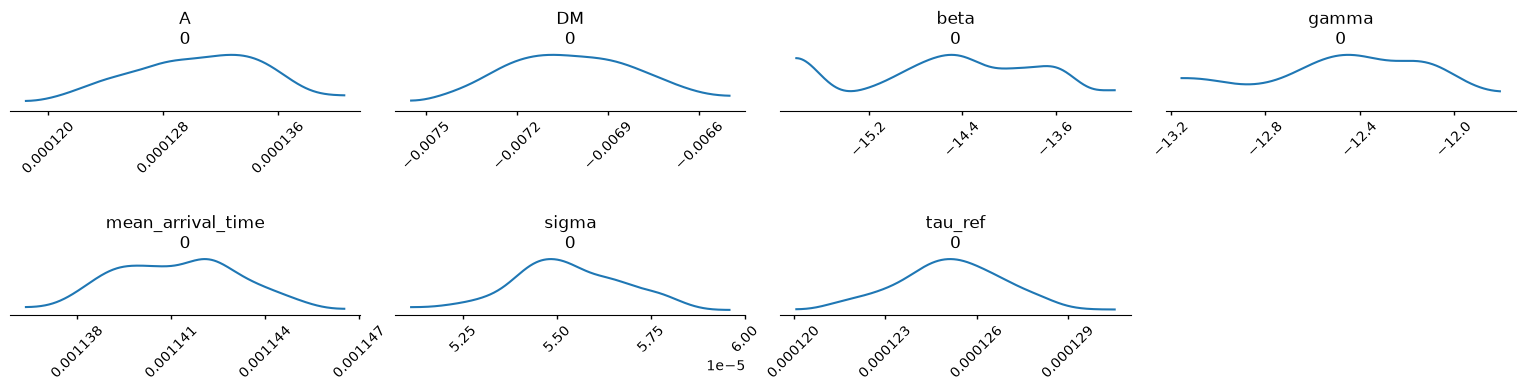

In [144]:
axes = azp.plot_dist(mcmc_data, stats=None)
for ax in plt.gcf().axes:
    ax.xaxis.set_major_locator(ticker.MaxNLocator(nbins=4))  # Limit to 4 ticks max
    ax.tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.subplots_adjust(wspace=0.1)
plt.subplots_adjust(hspace=2.5)

# Remove all "mean" text annotations across all subplots
for ax in plt.gcf().axes:
    for text in list(ax.texts):
        if "mean" in text.get_text():
            text.remove()
            # Remove horizontal interval lines (they only have 2 x-data points)
    for line in list(ax.lines):
        if len(line.get_xdata()) <= 2:
            line.remove()
            # 3. Remove point estimate dots
    for collection in list(ax.collections):
        collection.remove()

plt.draw()

/mnt/home/hsiegel/FRBayes/.venv/lib/python3.13/site-packages/xarray/core/duck_array_ops.py:278: UserWarning: Explicitly requested dtype int64 requested in astype is not available, and will be truncated to dtype int32. To enable more dtypes, set the jax_enable_x64 configuration option or the JAX_ENABLE_X64 shell environment variable. See https://github.com/jax-ml/jax#current-gotchas for more.
  return xp.astype(data, dtype, **kwargs)
/mnt/home/hsiegel/FRBayes/.venv/lib/python3.13/site-packages/xarray/core/duck_array_ops.py:278: UserWarning: Explicitly requested dtype int64 requested in astype is not available, and will be truncated to dtype int32. To enable more dtypes, set the jax_enable_x64 configuration option or the JAX_ENABLE_X64 shell environment variable. See https://github.com/jax-ml/jax#current-gotchas for more.
  return xp.astype(data, dtype, **kwargs)
/mnt/home/hsiegel/FRBayes/.venv/lib/python3.13/site-packages/xarray/core/duck_array_ops.py:278: UserWarning: Explicitly reques

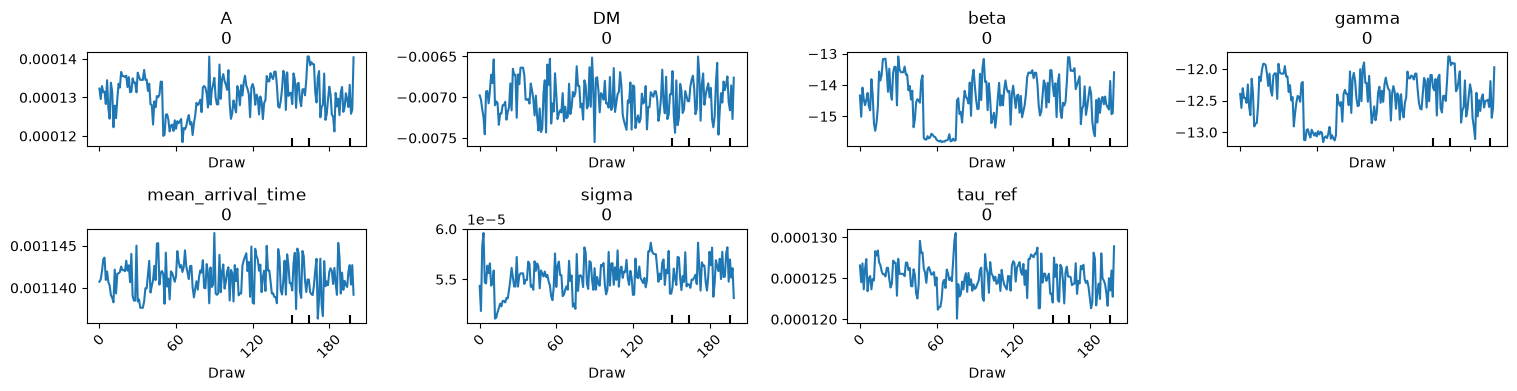

In [145]:
azp.plot_trace(mcmc_data)

# 2. Clean up x-axis tick clutter across all generated subplots
for ax in plt.gcf().axes:
    ax.xaxis.set_major_locator(ticker.MaxNLocator(nbins=4))
    ax.tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

## Plot Residual

Plotting for Posterior Draw #53
Max Data abs : 5.634737
Max Model abs: 2.7236016


/tmp/ipykernel_44946/612648999.py:118: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


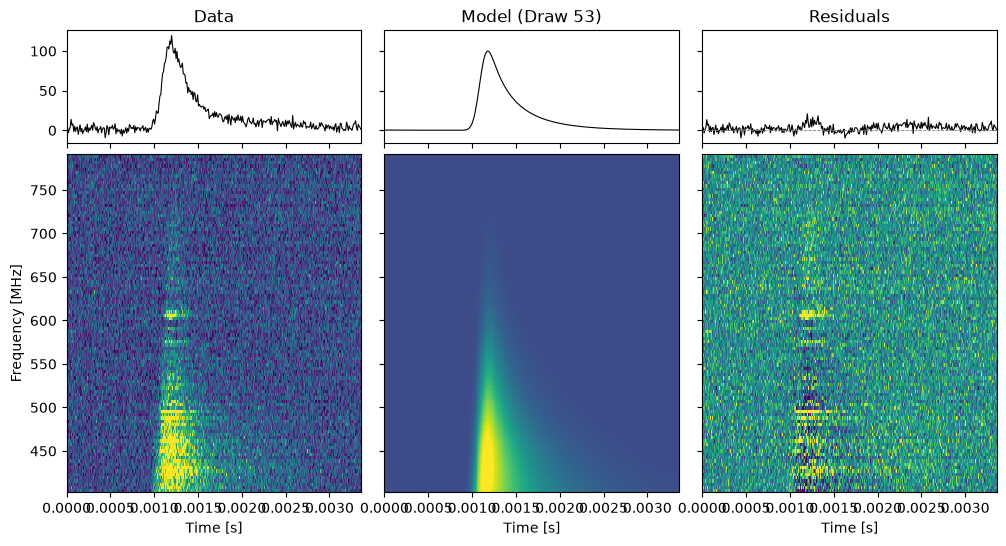

In [146]:
# -------------------------------------------------------------------
# 1. Extract a Random Posterior Draw & Squeeze Parameters to Scalars
# -------------------------------------------------------------------
# samples = mcmc.get_samples()
num_draws = len(next(iter(samples.values())))

draw_idx = random.randint(0, num_draws - 1)
print(f"Plotting for Posterior Draw #{draw_idx}")

# Use jnp.squeeze to strip trailing (1,) dimensions from parameters
test_params = {
    "mean_arrival_time": jnp.squeeze(samples["mean_arrival_time"][draw_idx]),
    "sigma": jnp.squeeze(samples["sigma"][draw_idx]),
    "DM": jnp.squeeze(samples["DM"][draw_idx]),
    "tau_ref": jnp.squeeze(samples["tau_ref"][draw_idx]),
    "gamma": jnp.squeeze(samples["gamma"][draw_idx]),
    "beta": jnp.squeeze(samples["beta"][draw_idx]),
    "freq_ref": jnp.float32(600.0),
    "A": jnp.squeeze(samples["A"][draw_idx]),
}

# Forward model evaluation
M_FD = single_pulse_fn(test_params)
M_TD = (1.0 / dt) * jnp.fft.irfft(M_FD, n=Nseg, axis=-1)
data_TD = (1.0 / dt) * jnp.fft.irfft(data_reshaped_FFT, n=Nseg, axis=-1)

data_TD_plot = data_TD
model_TD_plot = M_TD
time_plot = time_rel
freq_plot = jnp.squeeze(freq)

# Quick amplitude check diagnostic
print("Max Data abs :", jnp.max(jnp.abs(data_TD_plot)))
print("Max Model abs:", jnp.max(jnp.abs(model_TD_plot)))

# -------------------------------------------------------------------
# 2. Residuals & Frequency Collapsed Time Series
# -------------------------------------------------------------------
resid_TD_plot = data_TD_plot - model_TD_plot

data_ts = jnp.nansum(data_TD_plot, axis=0)
model_ts = jnp.nansum(model_TD_plot, axis=0)
resid_ts = data_ts - model_ts

# Data & Model limits
vmin, vmax = jnp.nanpercentile(data_TD_plot, jnp.array([1.0, 99.0]))

# Independent zero-centered limits for Residuals
vmax_res = jnp.nanpercentile(jnp.abs(resid_TD_plot), 99.0)

# -------------------------------------------------------------------
# 3. Figure Layout & Plotting
# -------------------------------------------------------------------
fig = plt.figure(figsize=(12, 6))
gs = gridspec.GridSpec(
    2,
    3,
    height_ratios=[1, 3],
    hspace=0.05,
    wspace=0.08,
    figure=fig,
)

ax_ts_data = fig.add_subplot(gs[0, 0])
ax_ts_model = fig.add_subplot(gs[0, 1], sharey=ax_ts_data)
ax_ts_resid = fig.add_subplot(gs[0, 2], sharey=ax_ts_data)

ax_wf_data = fig.add_subplot(gs[1, 0], sharex=ax_ts_data)
ax_wf_model = fig.add_subplot(gs[1, 1], sharex=ax_ts_model, sharey=ax_wf_data)
ax_wf_resid = fig.add_subplot(gs[1, 2], sharex=ax_ts_resid, sharey=ax_wf_data)

# --- Top row: Time series ---
ax_ts_data.plot(time_plot, data_ts, color="k", lw=0.8)
ax_ts_model.plot(time_plot, model_ts, color="k", lw=0.8)
ax_ts_resid.plot(time_plot, resid_ts, color="k", lw=0.8)
ax_ts_resid.axhline(0, color="gray", lw=0.6, ls="--")

# --- Bottom row: Waterfalls ---
imshow_data_kwargs = dict(
    aspect="auto",
    origin="lower",
    interpolation="nearest",
    cmap="viridis",
    vmin=vmin,
    vmax=vmax,
    extent=(time_plot[0], time_plot[-1], freq_plot[0], freq_plot[-1]),
)

imshow_resid_kwargs = dict(
    aspect="auto",
    origin="lower",
    interpolation="nearest",
    cmap="viridis",
    vmin=-vmax_res,
    vmax=vmax_res,
    extent=(time_plot[0], time_plot[-1], freq_plot[0], freq_plot[-1]),
)

ax_wf_data.imshow(data_TD_plot, **imshow_data_kwargs)
ax_wf_model.imshow(model_TD_plot, **imshow_data_kwargs)
ax_wf_resid.imshow(resid_TD_plot, **imshow_resid_kwargs)

# --- Formatting ---
ax_ts_model.set_title(f"Model (Draw {draw_idx})")
ax_ts_data.set_title("Data")
ax_ts_resid.set_title("Residuals")

ax_wf_data.set_xlabel("Time [s]")
ax_wf_model.set_xlabel("Time [s]")
ax_wf_resid.set_xlabel("Time [s]")
ax_wf_data.set_ylabel("Frequency [MHz]")

for ax in (ax_ts_data, ax_ts_model, ax_ts_resid):
    ax.tick_params(labelbottom=False)
for ax in (ax_ts_model, ax_wf_model, ax_ts_resid, ax_wf_resid):
    ax.tick_params(labelleft=False)

plt.tight_layout()
plt.show()

## Test priors

/tmp/ipykernel_3342559/3600792235.py:108: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


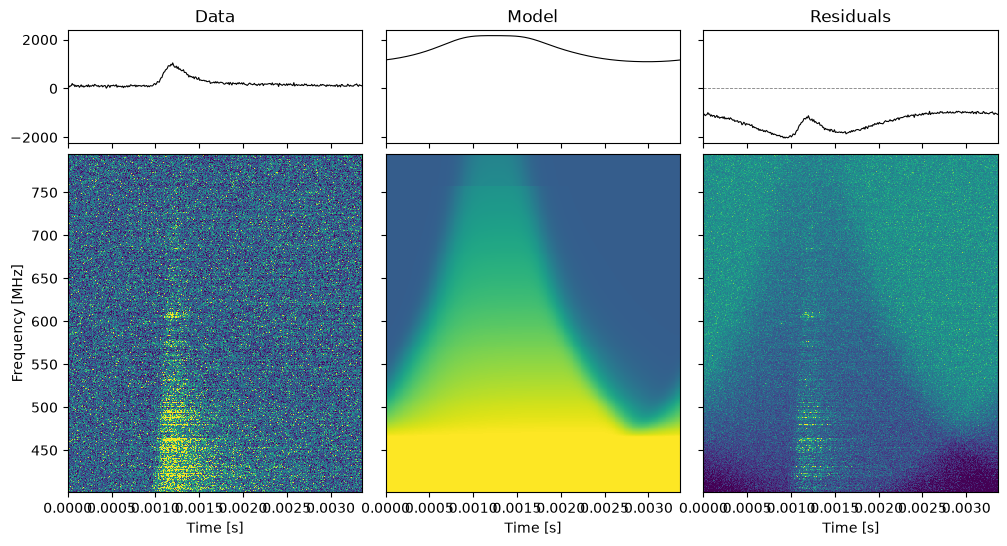

In [293]:

# -------------------------------------------------------------------
# 1. Forward Model Evaluation & IFFT Reconstruction
# -------------------------------------------------------------------
test_params = {
    "mean_arrival_time": jnp.float32(0.00115),  # (s)
    "sigma": jnp.float32(9.9871264e-05),  # (s)
    "DM": jnp.float32(-0.01),  # residual DM (pc cm^-3)
    "tau_ref": jnp.float32(0.00017),  # scattering timescale (s)
    "gamma": jnp.float32(-5.6108313),  # spectral index
    "beta": jnp.float32(-2.6474257),  # spectral running
    "freq_ref": jnp.float32(600.0),  # (MHz)
    "A": jnp.float32(4e-4*10),  # Explicit unmarginalized amplitude
}

# Evaluate unmarginalized Fourier model directly (A is inside test_params)
M_FD = single_pulse_fn(test_params)
M_TD = (1.0 / dt) * jnp.fft.irfft(M_FD, n=Nseg, axis=-1)

# Reconstruct baseline-subtracted data in Time Domain
data_TD = (1.0 / dt) * jnp.fft.irfft(data_reshaped_FFT, n=Nseg, axis=-1)

data_TD_plot = data_TD
model_TD_plot = M_TD
time_plot = time_rel
freq_plot = jnp.squeeze(freq)

# -------------------------------------------------------------------
# 2. Residuals & Frequency Collapsed Time Series
# -------------------------------------------------------------------
resid_TD_plot = data_TD_plot - model_TD_plot

# Frequency-summed time series
data_ts = jnp.nansum(data_TD_plot, axis=0)
model_ts = jnp.nansum(model_TD_plot, axis=0)
resid_ts = data_ts - model_ts

# Color limits: data/model scale vs. zero-centered residual scale
vmin, vmax = jnp.nanpercentile(data_TD_plot, jnp.array([1.0, 99.0]))
vmax_res = jnp.nanpercentile(jnp.abs(resid_TD_plot), 99.0)

# -------------------------------------------------------------------
# 3. Figure Layout & Plotting
# -------------------------------------------------------------------
fig = plt.figure(figsize=(12, 6))
gs = gridspec.GridSpec(
    2,
    3,
    height_ratios=[1, 3],
    hspace=0.05,
    wspace=0.08,
    figure=fig,
)

ax_ts_data = fig.add_subplot(gs[0, 0])
ax_ts_model = fig.add_subplot(gs[0, 1], sharey=ax_ts_data)
ax_ts_resid = fig.add_subplot(gs[0, 2], sharey=ax_ts_data)

ax_wf_data = fig.add_subplot(gs[1, 0], sharex=ax_ts_data)
ax_wf_model = fig.add_subplot(gs[1, 1], sharex=ax_ts_model, sharey=ax_wf_data)
ax_wf_resid = fig.add_subplot(gs[1, 2], sharex=ax_ts_resid, sharey=ax_wf_data)

# --- Top row: Frequency-summed time series ---
ax_ts_data.plot(time_plot, data_ts, color="k", lw=0.8)
ax_ts_model.plot(time_plot, model_ts, color="k", lw=0.8)
ax_ts_resid.plot(time_plot, resid_ts, color="k", lw=0.8)
ax_ts_resid.axhline(0, color="gray", lw=0.6, ls="--")

# --- Bottom row: Waterfalls ---
imshow_data_kwargs = dict(
    aspect="auto",
    origin="lower",
    interpolation="nearest",
    cmap="viridis",
    vmin=vmin,
    vmax=vmax,
    extent=(time_plot[0], time_plot[-1], freq_plot[0], freq_plot[-1]),
)

imshow_resid_kwargs = dict(
    aspect="auto",
    origin="lower",
    interpolation="nearest",
    cmap="viridis",  # Symmetric zero-centered colormap
    vmin=-vmax_res,
    vmax=vmax_res,
    extent=(time_plot[0], time_plot[-1], freq_plot[0], freq_plot[-1]),
)

ax_wf_data.imshow(data_TD_plot, **imshow_data_kwargs)
ax_wf_model.imshow(model_TD_plot, **imshow_data_kwargs)
ax_wf_resid.imshow(resid_TD_plot, **imshow_resid_kwargs)

# --- Formatting ---
ax_ts_data.set_title("Data")
ax_ts_model.set_title("Model")
ax_ts_resid.set_title("Residuals")

ax_wf_data.set_xlabel("Time [s]")
ax_wf_model.set_xlabel("Time [s]")
ax_wf_resid.set_xlabel("Time [s]")
ax_wf_data.set_ylabel("Frequency [MHz]")

for ax in (ax_ts_data, ax_ts_model, ax_ts_resid):
    ax.tick_params(labelbottom=False)
for ax in (ax_ts_model, ax_wf_model, ax_ts_resid, ax_wf_resid):
    ax.tick_params(labelleft=False)

plt.tight_layout()
plt.show()

# Setup fullnormal marginalized model and sampler

In [161]:
# -------------------------------------------------------------------
# 2. Model Closure Setup
# -------------------------------------------------------------------
constants_dict = {
    "freq_channels_ref": float(jnp.mean(freq_channels)),
    "delta": -4.0,
    "DM_incoherent": 0.0,
    "channel_width": float(jnp.abs(freq[1] - freq[0])),
}

single_pulse_fn = setup_model(
    constants_dict=constants_dict,
    freqs_channels=freq_channels,
    times=time_rel,
)

# -------------------------------------------------------------------
# 3. Priors & NUTS Sampling
# -------------------------------------------------------------------
# priors = {
#     "mean_arrival_time": dist.Uniform(0.05, 0.06),   # (s) across window
#     "sigma": dist.Uniform(5e-5, 5e-4),               # intrinsic width (s)
#     "DM": dist.Uniform(-0.05, 0.04),                 # residual DM (pc cm^-3)
#     "tau_ref": dist.Uniform(1e-4, 2.5e-4),           # scattering timescale (s)
#     "gamma": dist.Uniform(-8.0, -6.0),               # spectral index
#     "beta": dist.Uniform(-6.0, -4.0),                # spectral running
# }

# test_params = {
#     "mean_arrival_time": jnp.float32(0.00115),  # (s)
#     "sigma": jnp.float32(9.9871264e-05),             # (s)
#     "DM": jnp.float32(-0.01),                 # residual DM (pc cm^-3)
#     "tau_ref": jnp.float32(0.00017),          # scattering timescale (s)
#     "gamma": jnp.float32(-5.6108313),               # spectral index
#     "beta": jnp.float32(-2.6474257),                # spectral running
#     "freq_ref": jnp.float32(600)
# }

priors = {
    # TOA prior: Wide Gaussian centered at 1.15 ms with a 2 ms std dev
    "mean_arrival_time": dist.Uniform(0.00115-.0002, 0.00115+.0002),
    
    "sigma": dist.Uniform(5e-5, 1e-4),              # intrinsic width (s)
    "DM": dist.Uniform(-0.1, 0.1),                  # residual DM (pc cm^-3)
    "tau_ref": dist.Uniform(1e-5, 2e-4),            # scattering timescale (s)
    "gamma": dist.Uniform(-20.0, -2.0),             # spectral index
    "beta": dist.Uniform(-16.0, 1.0),                # spectral running

}
n_pulses = 1
s_opt = 100.0

num_warmup = 1000
num_samples = 200
num_chains = 1

kernel = NUTS(FD_marg_fullnormal_gaussianlikelihood, dense_mass=True)
mcmc = MCMC(kernel, num_warmup=num_warmup, num_samples=num_samples, num_chains=num_chains, 
            chain_method="parallel")

# Fixed master key seed for reproducible sampling across runs
key_sampler, key_fluences = jax.random.split(jax.random.PRNGKey(1))

## Run Marginalized

In [162]:
mcmc.run(
    key_sampler,
    data_fd=data_reshaped_FFT,
    sigma_noise=sigma_noise,
    n_time=Nseg,
    n_pulses=n_pulses,
    priors=priors,
    single_pulse_fn=single_pulse_fn,
    s_opt=s_opt,
    extra_fields=("num_steps","accept_prob","diverging","potential_energy")
)

sample: 100%|██████████| 1200/1200 [00:19<00:00, 60.08it/s, 7 steps of size 3.49e-01. acc. prob=0.89]  


In [163]:
# -------------------------------------------------------------------
# 4. Extract Posteriors
# -------------------------------------------------------------------
samples = mcmc.get_samples()
extra = mcmc.get_extra_fields()

In [164]:
mcmc_data = az.from_numpyro(mcmc, log_likelihood={}, posterior_predictive={})

In [165]:
az.summary(mcmc_data, round_to=3)

/mnt/home/hsiegel/FRBayes/.venv/lib/python3.13/site-packages/arviz_stats/base/diagnostics.py:312: RuntimeWarning: overflow encountered in power
  varvar = ((sims_c**4).mean() - evar**2) / ess
/mnt/home/hsiegel/FRBayes/.venv/lib/python3.13/site-packages/arviz_stats/base/diagnostics.py:312: RuntimeWarning: overflow encountered in scalar power
  varvar = ((sims_c**4).mean() - evar**2) / ess
/mnt/home/hsiegel/FRBayes/.venv/lib/python3.13/site-packages/arviz_stats/base/diagnostics.py:312: RuntimeWarning: invalid value encountered in scalar subtract
  varvar = ((sims_c**4).mean() - evar**2) / ess


,mean,sd,eti89_lb,eti89_ub,ess_bulk,ess_tail,r_hat,mcse_mean,mcse_sd
DM[0],-7.000000e-03,0.000000e+00,-7.000000e-03,-7.000000e-03,124.284,142.588,NaN,0.000000e+00,0.000
beta[0],-1.438800e+01,7.340000e-01,-1.553900e+01,-1.317900e+01,44.016,31.767,NaN,1.090000e-01,0.058
gamma[0],-1.241700e+01,3.470000e-01,-1.293500e+01,-1.185000e+01,43.730,49.675,NaN,5.000000e-02,0.029
"gram[0, 0]",2.194602e+12,1.598608e+11,1.954680e+12,2.430752e+12,59.334,66.555,NaN,2.068851e+10,NaN
mean_arrival_time[0],1.000000e-03,0.000000e+00,1.000000e-03,1.000000e-03,138.956,120.487,NaN,0.000000e+00,0.000
rho_mf[0],2.868987e+08,1.046615e+07,2.709173e+08,3.021314e+08,59.432,66.555,NaN,1.356912e+06,684942.083
sigma[0],0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,119.211,70.437,NaN,0.000000e+00,0.000
snr_mf[0],1.937940e+02,9.000000e-03,1.937770e+02,1.938050e+02,74.431,66.600,NaN,1.000000e-03,0.001
snr_opt[0],1.480434e+06,5.400406e+04,1.398099e+06,1.559087e+06,59.334,66.555,NaN,7.002126e+03,3533.680
tau_ref[0],0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,172.679,134.750,NaN,0.000000e+00,0.000


In [166]:
jnp.corrcoef(samples["gamma"][:,0], samples["beta"][:,0])[0,1]

Array(0.9839986, dtype=float32)

In [152]:
ex = mcmc.get_extra_fields()
ns = jnp.array(ex["num_steps"])
print(f"gradients/sample: mean {ns.mean():.1f}  median {jnp.median(ns)}  max {ns.max()}")
print(f"at max tree depth: {100*jnp.mean(ns >= 2**10 - 1):.1f}%")   # adjust if max_tree_depth != 10
print(f"accept_prob: mean {jnp.array(ex['accept_prob']).mean():.3f}")
print(f"divergences: {int(jnp.array(ex['diverging']).sum())} / {len(ns)}")
print(f"step size: {float(mcmc.last_state.adapt_state.step_size):.3e}")
print(f"potential_energy: mean {jnp.array(ex['potential_energy']).mean():.1f}  sd {jnp.array(ex['potential_energy']).std():.2f}")

gradients/sample: mean 9.8  median 7.0  max 23
at max tree depth: 0.0%
accept_prob: mean 0.893
divergences: 0 / 200
step size: 3.492e-01
potential_energy: mean -18760.9  sd 1.77


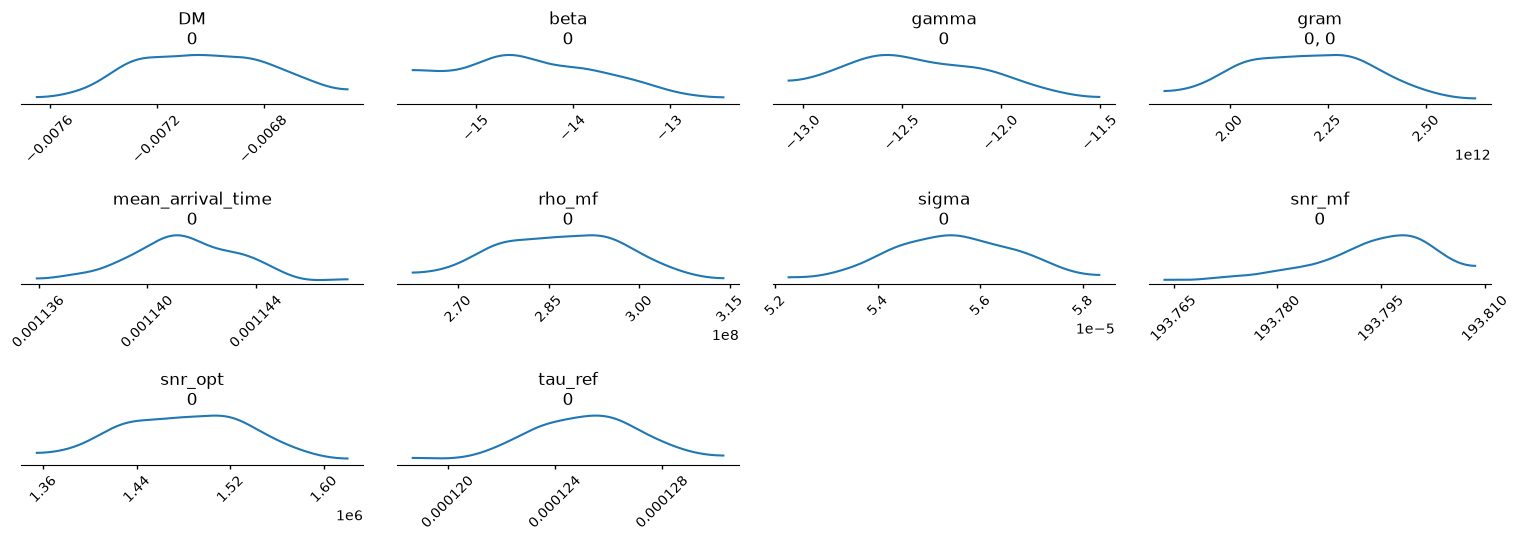

In [153]:
axes = azp.plot_dist(mcmc_data, stats=None)
for ax in plt.gcf().axes:
    ax.xaxis.set_major_locator(ticker.MaxNLocator(nbins=4))  # Limit to 4 ticks max
    ax.tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.subplots_adjust(wspace=0.1)
plt.subplots_adjust(hspace=2.5)

# Remove all "mean" text annotations across all subplots
for ax in plt.gcf().axes:
    for text in list(ax.texts):
        if "mean" in text.get_text():
            text.remove()
            # Remove horizontal interval lines (they only have 2 x-data points)
    for line in list(ax.lines):
        if len(line.get_xdata()) <= 2:
            line.remove()
            # 3. Remove point estimate dots
    for collection in list(ax.collections):
        collection.remove()

plt.draw()

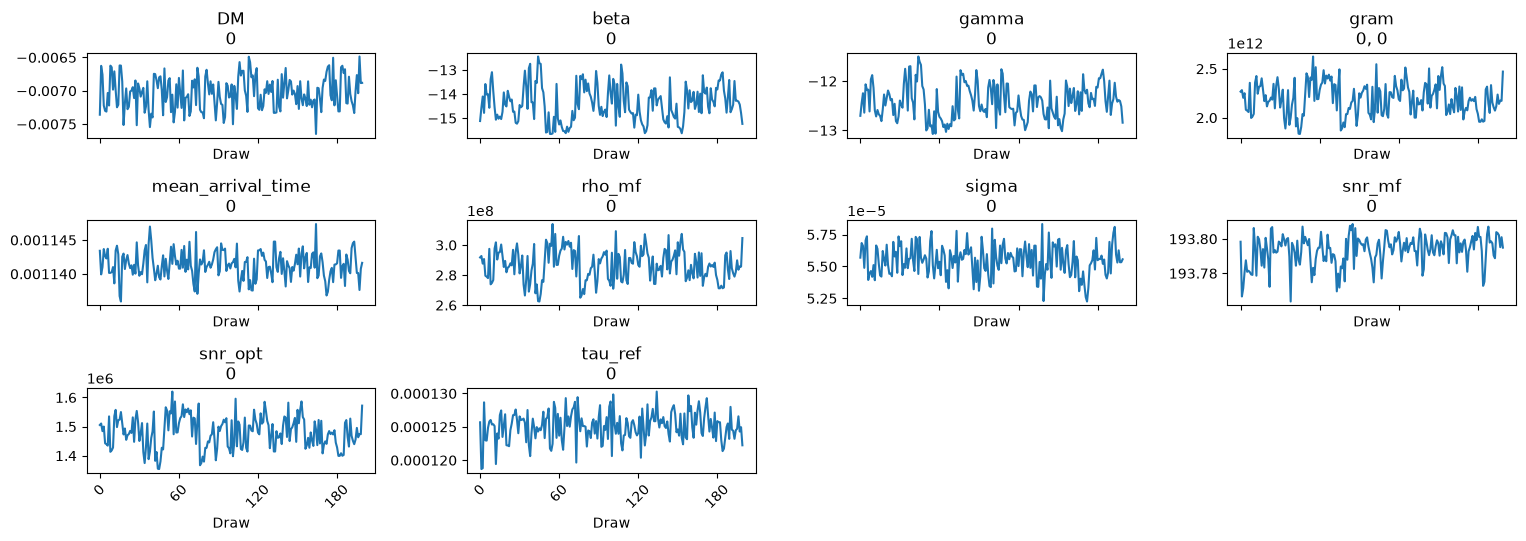

In [154]:
azp.plot_trace(mcmc_data)

# 2. Clean up x-axis tick clutter across all generated subplots
for ax in plt.gcf().axes:
    ax.xaxis.set_major_locator(ticker.MaxNLocator(nbins=4))
    ax.tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

In [155]:
# -------------------------------------------------------------------
# 4. Reconstruct Fluences
# -------------------------------------------------------------------

fluences, accepts = draw_fluences_fullnormal_gaussmarg(
    gram=samples["gram"],
    rho=samples["rho_mf"],
    s_opt=s_opt,
    key=key_fluences,
)

physical_fluences = fluences[accepts]
print(f"Sampling complete. Retained {jnp.sum(accepts)} / {len(accepts)} physical fluence draws.")

Sampling complete. Retained 200 / 200 physical fluence draws.


In [156]:
physical_fluences

Array([[0.00012734],
       [0.00012774],
       [0.0001301 ],
       [0.00012794],
       [0.00013493],
       [0.00013462],
       [0.00013453],
       [0.0001248 ],
       [0.00013647],
       [0.0001369 ],
       [0.00013595],
       [0.00012489],
       [0.00012482],
       [0.00012825],
       [0.00012727],
       [0.00012788],
       [0.00012593],
       [0.00012897],
       [0.00013155],
       [0.00013139],
       [0.00013378],
       [0.00013263],
       [0.00013007],
       [0.00013059],
       [0.00013099],
       [0.00012636],
       [0.00013354],
       [0.00012731],
       [0.0001249 ],
       [0.00012708],
       [0.00013424],
       [0.00013071],
       [0.00012886],
       [0.00013596],
       [0.00014154],
       [0.00013405],
       [0.00012749],
       [0.00013936],
       [0.00013731],
       [0.00013216],
       [0.0001311 ],
       [0.00012448],
       [0.00013993],
       [0.00013745],
       [0.00014403],
       [0.00014415],
       [0.00013966],
       [0.000

## Plot Residual

Plotting for Posterior Draw #189


/tmp/ipykernel_44946/1750914428.py:111: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


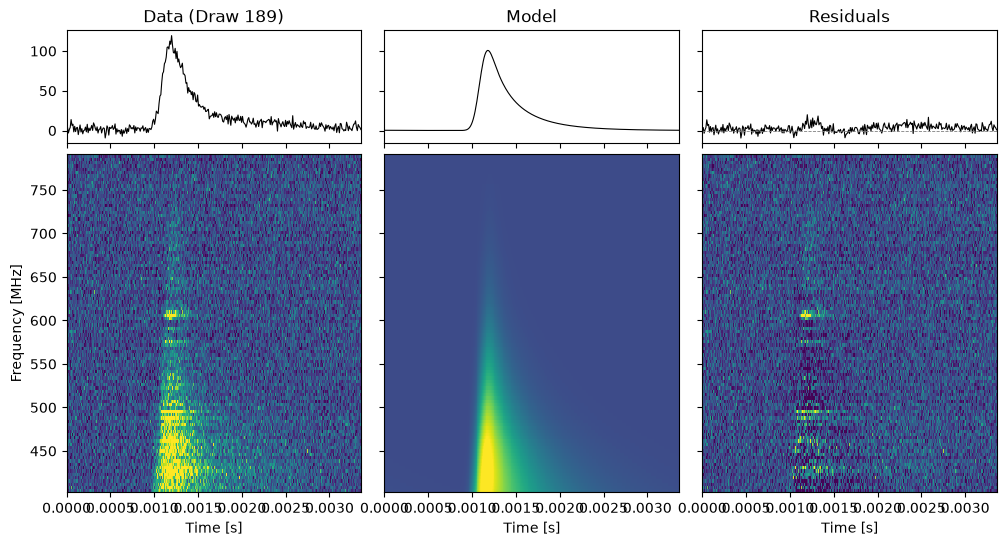

In [158]:
# -------------------------------------------------------------------
# 1. Extract a Random Posterior Draw & Evaluate Forward Model
# -------------------------------------------------------------------
# samples = mcmc.get_samples()
num_draws = len(next(iter(samples.values())))

# Pick a draw index using JAX random
key = jax.random.PRNGKey(0)
draw_idx = int(jax.random.randint(key, shape=(), minval=0, maxval=num_draws))
print(f"Plotting for Posterior Draw #{draw_idx}")

# Extract parameters for the chosen draw directly as JAX scalars
test_params = {
    "mean_arrival_time": samples["mean_arrival_time"][draw_idx],
    "sigma": samples["sigma"][draw_idx],
    "DM": samples["DM"][draw_idx],
    "tau_ref": samples["tau_ref"][draw_idx],
    "gamma": samples["gamma"][draw_idx],
    "beta": samples["beta"][draw_idx],
    "freq_ref": jnp.float32(600.0),
}
A_scale = physical_fluences[draw_idx]

# Extract amplitude scale from posterior ('gram' or fallback to default)
# A_scale = (
#     samples["gram"][draw_idx] if "gram" in samples else jnp.float32(4e-4)
# )

# Evaluate model in Fourier domain and transform to Time Domain
M_FD = single_pulse_fn(test_params) * A_scale
M_TD = (1.0 / dt) * jnp.fft.irfft(M_FD, n=Nseg, axis=-1)

# Reconstruct baseline-subtracted data in Time Domain
data_TD = (1.0 / dt) * jnp.fft.irfft(data_reshaped_FFT, n=Nseg, axis=-1)

data_TD_plot = data_TD
model_TD_plot = M_TD
time_plot = time_rel
freq_plot = jnp.squeeze(freq)

# -------------------------------------------------------------------
# 2. Residuals & Frequency Collapsed Time Series
# -------------------------------------------------------------------
resid_TD_plot = data_TD_plot - model_TD_plot

# Frequency-summed time series
data_ts = jnp.nansum(data_TD_plot, axis=0)
model_ts = jnp.nansum(model_TD_plot, axis=0)
resid_ts = data_ts - model_ts

# Shared robust color limits using jnp
vmin, vmax = jnp.nanpercentile(data_TD_plot, jnp.array([1.0, 99.0]))

# -------------------------------------------------------------------
# 3. Figure Layout & Plotting
# -------------------------------------------------------------------
fig = plt.figure(figsize=(12, 6))
gs = gridspec.GridSpec(
    2,
    3,
    height_ratios=[1, 3],
    hspace=0.05,
    wspace=0.08,
    figure=fig,
)

ax_ts_data = fig.add_subplot(gs[0, 0])
ax_ts_model = fig.add_subplot(gs[0, 1], sharey=ax_ts_data)
ax_ts_resid = fig.add_subplot(gs[0, 2], sharey=ax_ts_data)

ax_wf_data = fig.add_subplot(gs[1, 0], sharex=ax_ts_data)
ax_wf_model = fig.add_subplot(gs[1, 1], sharex=ax_ts_model, sharey=ax_wf_data)
ax_wf_resid = fig.add_subplot(gs[1, 2], sharex=ax_ts_resid, sharey=ax_wf_data)

# --- Top row: Frequency-summed time series ---
ax_ts_data.plot(time_plot, data_ts, color="k", lw=0.8)
ax_ts_model.plot(time_plot, model_ts, color="k", lw=0.8)
ax_ts_resid.plot(time_plot, resid_ts, color="k", lw=0.8)
ax_ts_resid.axhline(0, color="gray", lw=0.6, ls="--")

# --- Bottom row: Waterfalls ---
imshow_kwargs = dict(
    aspect="auto",
    origin="lower",
    interpolation="nearest",
    cmap="viridis",
    vmin=vmin,
    vmax=vmax,
    extent=(time_plot[0], time_plot[-1], freq_plot[0], freq_plot[-1]),
)

ax_wf_data.imshow(data_TD_plot, **imshow_kwargs)
ax_wf_model.imshow(model_TD_plot, **imshow_kwargs)
ax_wf_resid.imshow(resid_TD_plot, **imshow_kwargs)

# --- Formatting ---
ax_ts_data.set_title(f"Data (Draw {draw_idx})")
ax_ts_model.set_title("Model")
ax_ts_resid.set_title("Residuals")

ax_wf_data.set_xlabel("Time [s]")
ax_wf_model.set_xlabel("Time [s]")
ax_wf_resid.set_xlabel("Time [s]")
ax_wf_data.set_ylabel("Frequency [MHz]")

for ax in (ax_ts_data, ax_ts_model, ax_ts_resid):
    ax.tick_params(labelbottom=False)
for ax in (ax_ts_model, ax_wf_model, ax_ts_resid, ax_wf_resid):
    ax.tick_params(labelleft=False)

plt.tight_layout()
plt.show()

## Test priors

/tmp/ipykernel_3740517/1299604607.py:117: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


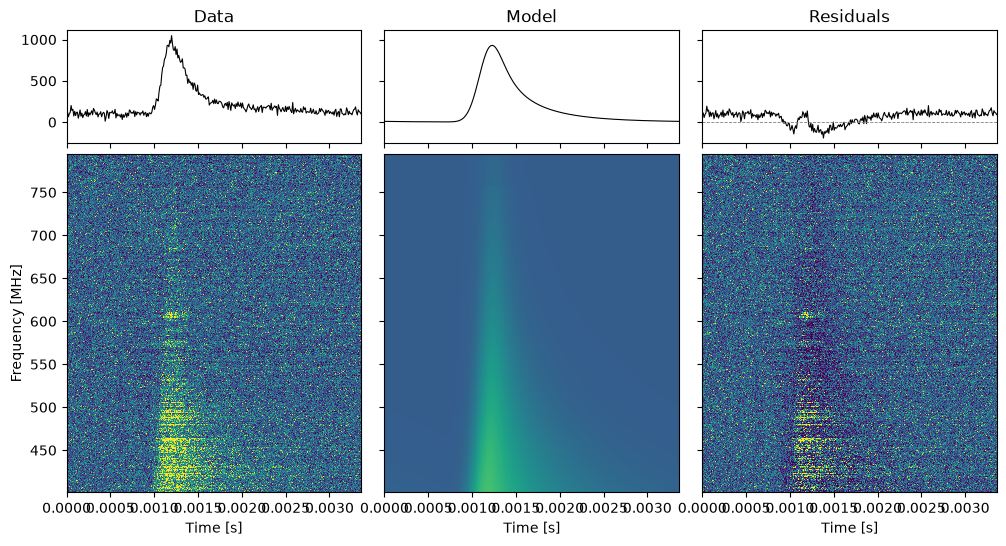

In [26]:

# -------------------------------------------------------------------
# 1. Forward Model Evaluation & IFFT Reconstruction
# -------------------------------------------------------------------
# Set test parameters matching your prior bounds
test_params = {
    "mean_arrival_time": jnp.float32(0.00115),  # (s)
    "sigma": jnp.float32(9.9871264e-05),             # (s)
    "DM": jnp.float32(-0.01),                 # residual DM (pc cm^-3)
    "tau_ref": jnp.float32(0.00017),          # scattering timescale (s)
    "gamma": jnp.float32(-5.6108313),               # spectral index
    "beta": jnp.float32(-2.6474257),                # spectral running
    "freq_ref": jnp.float32(600)
}

# Optional fluence scale (unit-template from setup_model scaled to data level)
A_scale = 4e-4

# Evaluate model in Fourier domain and transform to Time Domain
M_FD = single_pulse_fn(test_params) * A_scale
M_TD = (1.0 / dt) * jnp.fft.irfft(M_FD, n=Nseg, axis=-1)

# Reconstruct baseline-subtracted data in Time Domain
data_TD = (1.0 / dt) * jnp.fft.irfft(data_reshaped_FFT, n=Nseg, axis=-1)

# Convert to NumPy for Matplotlib rendering
data_TD_plot = np.asarray(data_TD)
model_TD_plot = np.asarray(M_TD)
time_plot = np.asarray(time_rel)
freq_plot = np.asarray(freq).squeeze()

# -------------------------------------------------------------------
# 2. Residuals & Frequency Collapsed Time Series
# -------------------------------------------------------------------
resid_TD_plot = data_TD_plot - model_TD_plot

# Frequency-summed time series
data_ts = np.nansum(data_TD_plot, axis=0)
model_ts = np.nansum(model_TD_plot, axis=0)
resid_ts = data_ts - model_ts

# Shared robust color limits
lo_pct, hi_pct = 1, 99
vmin, vmax = np.nanpercentile(data_TD_plot, [lo_pct, hi_pct])

# -------------------------------------------------------------------
# 3. Figure Layout & Plotting
# -------------------------------------------------------------------
fig = plt.figure(figsize=(12, 6))
gs = gridspec.GridSpec(
    2, 3,
    height_ratios=[1, 3],
    hspace=0.05, wspace=0.08,
    figure=fig,
)

ax_ts_data  = fig.add_subplot(gs[0, 0])
ax_ts_model = fig.add_subplot(gs[0, 1], sharey=ax_ts_data)
ax_ts_resid = fig.add_subplot(gs[0, 2], sharey=ax_ts_data)

ax_wf_data  = fig.add_subplot(gs[1, 0], sharex=ax_ts_data)
ax_wf_model = fig.add_subplot(gs[1, 1], sharex=ax_ts_model, sharey=ax_wf_data)
ax_wf_resid = fig.add_subplot(gs[1, 2], sharex=ax_ts_resid, sharey=ax_wf_data)

# --- Top row: Frequency-summed time series ---
ax_ts_data.plot(time_plot, data_ts, color="k", lw=0.8)
ax_ts_model.plot(time_plot, model_ts, color="k", lw=0.8)
ax_ts_resid.plot(time_plot, resid_ts, color="k", lw=0.8)
ax_ts_resid.axhline(0, color="gray", lw=0.6, ls="--")

# --- Bottom row: Waterfalls ---
imshow_kwargs = dict(
    aspect="auto",
    origin="lower",
    interpolation="nearest",
    cmap="viridis",
    vmin=vmin,
    vmax=vmax,
    extent=(time_plot[0], time_plot[-1], freq_plot[0], freq_plot[-1]),
)

ax_wf_data.imshow(data_TD_plot, **imshow_kwargs)
ax_wf_model.imshow(model_TD_plot, **imshow_kwargs)
ax_wf_resid.imshow(resid_TD_plot, **imshow_kwargs)

# --- Formatting ---
ax_ts_data.set_title("Data")
ax_ts_model.set_title("Model")
ax_ts_resid.set_title("Residuals")

ax_wf_data.set_xlabel("Time [s]")
ax_wf_model.set_xlabel("Time [s]")
ax_wf_resid.set_xlabel("Time [s]")
ax_wf_data.set_ylabel("Frequency [MHz]")

for ax in (ax_ts_data, ax_ts_model, ax_ts_resid):
    ax.tick_params(labelbottom=False)
for ax in (ax_ts_model, ax_wf_model, ax_ts_resid, ax_wf_resid):
    ax.tick_params(labelleft=False)

plt.tight_layout()
plt.show()

# Setup halfnormal marginalized model and sampler

In [225]:
# -------------------------------------------------------------------
# 2. Model Closure Setup
# -------------------------------------------------------------------
constants_dict = {
    "freq_channels_ref": float(jnp.mean(freq_channels)),
    "delta": -4.0,
    "DM_incoherent": 0.0,
    "channel_width": float(jnp.abs(freq[1] - freq[0])),
}

single_pulse_fn = setup_model(
    constants_dict=constants_dict,
    freqs_channels=freq_channels,
    times=time_rel,
)

# -------------------------------------------------------------------
# 3. Priors & NUTS Sampling
# -------------------------------------------------------------------
# priors = {
#     "mean_arrival_time": dist.Uniform(0.05, 0.06),   # (s) across window
#     "sigma": dist.Uniform(5e-5, 5e-4),               # intrinsic width (s)
#     "DM": dist.Uniform(-0.05, 0.04),                 # residual DM (pc cm^-3)
#     "tau_ref": dist.Uniform(1e-4, 2.5e-4),           # scattering timescale (s)
#     "gamma": dist.Uniform(-8.0, -6.0),               # spectral index
#     "beta": dist.Uniform(-6.0, -4.0),                # spectral running
# }

# test_params = {
#     "mean_arrival_time": jnp.float32(0.00115),  # (s)
#     "sigma": jnp.float32(9.9871264e-05),             # (s)
#     "DM": jnp.float32(-0.01),                 # residual DM (pc cm^-3)
#     "tau_ref": jnp.float32(0.00017),          # scattering timescale (s)
#     "gamma": jnp.float32(-5.6108313),               # spectral index
#     "beta": jnp.float32(-2.6474257),                # spectral running
#     "freq_ref": jnp.float32(600)
# }

priors = {
    # TOA prior: Wide Gaussian centered at 1.15 ms with a 2 ms std dev
    "mean_arrival_time": dist.Uniform(0.00115-.0002, 0.00115+.0002),
    
    "sigma": dist.Uniform(5e-5, 1e-4),              # intrinsic width (s)
    "DM": dist.Uniform(-0.1, 0.1),                  # residual DM (pc cm^-3)
    "tau_ref": dist.Uniform(1e-5, 2e-4),            # scattering timescale (s)
    "gamma": dist.Uniform(-20.0, -2.0),             # spectral index
    "beta": dist.Uniform(-16.0, 1.0),                # spectral running
}
n_pulses = 1
s_opt = 100.0

num_warmup = 1000
num_samples = 200
num_chains = 1

kernel = NUTS(FD_marg_halfnormal_nooverlap_gaussianlikelihood, dense_mass=True)
mcmc = MCMC(kernel, num_warmup=num_warmup, num_samples=num_samples, num_chains=num_chains, 
            chain_method="parallel")

# Fixed master key seed for reproducible sampling across runs
key_sampler, key_fluences = jax.random.split(jax.random.PRNGKey(1))

## Run Marginalized

In [226]:
mcmc.run(
    key_sampler,
    data_fd=data_reshaped_FFT,
    sigma_noise=sigma_noise,
    n_time=Nseg,
    n_pulses=n_pulses,
    priors=priors,
    single_pulse_fn=single_pulse_fn,
    s_opt=s_opt,
    extra_fields=("num_steps","accept_prob","diverging","potential_energy")
)

sample: 100%|██████████| 1200/1200 [00:18<00:00, 64.35it/s, 7 steps of size 4.32e-01. acc. prob=0.90] 


In [227]:
# -------------------------------------------------------------------
# 4. Extract Posteriors
# -------------------------------------------------------------------
samples = mcmc.get_samples()
extra = mcmc.get_extra_fields()

In [228]:
mcmc_data = az.from_numpyro(mcmc, log_likelihood={}, posterior_predictive={})

In [229]:
az.summary(mcmc_data, round_to=3)

/mnt/home/hsiegel/FRBayes/.venv/lib/python3.13/site-packages/arviz_stats/base/diagnostics.py:312: RuntimeWarning: overflow encountered in power
  varvar = ((sims_c**4).mean() - evar**2) / ess
/mnt/home/hsiegel/FRBayes/.venv/lib/python3.13/site-packages/arviz_stats/base/diagnostics.py:312: RuntimeWarning: overflow encountered in scalar power
  varvar = ((sims_c**4).mean() - evar**2) / ess
/mnt/home/hsiegel/FRBayes/.venv/lib/python3.13/site-packages/arviz_stats/base/diagnostics.py:312: RuntimeWarning: invalid value encountered in scalar subtract
  varvar = ((sims_c**4).mean() - evar**2) / ess


,mean,sd,eti89_lb,eti89_ub,ess_bulk,ess_tail,r_hat,mcse_mean,mcse_sd
DM[0],-7.000000e-03,0.000000e+00,-7.000000e-03,-7.000000e-03,275.683,158.939,NaN,0.000000e+00,0.000
beta[0],-1.449200e+01,7.400000e-01,-1.569500e+01,-1.341600e+01,25.333,14.884,NaN,1.430000e-01,0.079
gamma[0],-1.247000e+01,3.430000e-01,-1.302400e+01,-1.193500e+01,27.344,25.573,NaN,6.500000e-02,0.037
"gram[0, 0]",2.220921e+12,1.640928e+11,1.965181e+12,2.488307e+12,35.975,53.172,NaN,2.806642e+10,NaN
mean_arrival_time[0],1.000000e-03,0.000000e+00,1.000000e-03,1.000000e-03,296.481,167.923,NaN,0.000000e+00,0.000
rho_mf[0],2.886088e+08,1.064327e+07,2.716591e+08,3.056869e+08,36.080,53.172,NaN,1.812656e+06,903361.102
sigma[0],0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,271.178,181.440,NaN,0.000000e+00,0.000
snr_mf[0],1.937930e+02,1.000000e-02,1.937740e+02,1.938050e+02,70.439,92.515,NaN,1.000000e-03,0.001
snr_opt[0],1.489263e+06,5.492778e+04,1.401849e+06,1.577436e+06,35.975,53.172,NaN,9.358927e+03,4664.117
tau_ref[0],0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,189.399,94.371,NaN,0.000000e+00,0.000


In [230]:
jnp.corrcoef(samples["gamma"][:,0], samples["beta"][:,0])[0,1]

Array(0.9809228, dtype=float32)

In [231]:
ex = mcmc.get_extra_fields()
ns = jnp.array(ex["num_steps"])
print(f"gradients/sample: mean {ns.mean():.1f}  median {jnp.median(ns)}  max {ns.max()}")
print(f"at max tree depth: {100*jnp.mean(ns >= 2**10 - 1):.1f}%")   # adjust if max_tree_depth != 10
print(f"accept_prob: mean {jnp.array(ex['accept_prob']).mean():.3f}")
print(f"divergences: {int(jnp.array(ex['diverging']).sum())} / {len(ns)}")
print(f"step size: {float(mcmc.last_state.adapt_state.step_size):.3e}")
print(f"potential_energy: mean {jnp.array(ex['potential_energy']).mean():.1f}  sd {jnp.array(ex['potential_energy']).std():.2f}")

gradients/sample: mean 8.0  median 7.0  max 31
at max tree depth: 0.0%
accept_prob: mean 0.899
divergences: 0 / 200
step size: 4.318e-01
potential_energy: mean -18761.4  sd 2.11


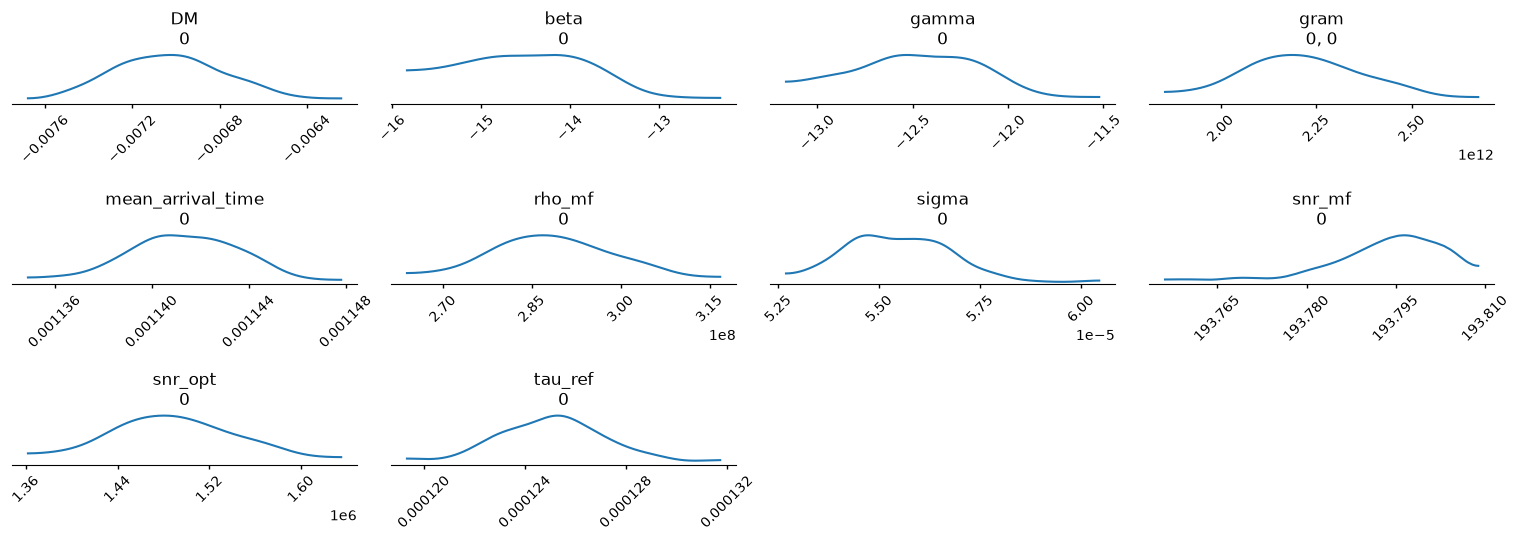

In [232]:
axes = azp.plot_dist(mcmc_data, stats=None)
for ax in plt.gcf().axes:
    ax.xaxis.set_major_locator(ticker.MaxNLocator(nbins=4))  # Limit to 4 ticks max
    ax.tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.subplots_adjust(wspace=0.1)
plt.subplots_adjust(hspace=2.5)

# Remove all "mean" text annotations across all subplots
for ax in plt.gcf().axes:
    for text in list(ax.texts):
        if "mean" in text.get_text():
            text.remove()
            # Remove horizontal interval lines (they only have 2 x-data points)
    for line in list(ax.lines):
        if len(line.get_xdata()) <= 2:
            line.remove()
            # 3. Remove point estimate dots
    for collection in list(ax.collections):
        collection.remove()

plt.draw()

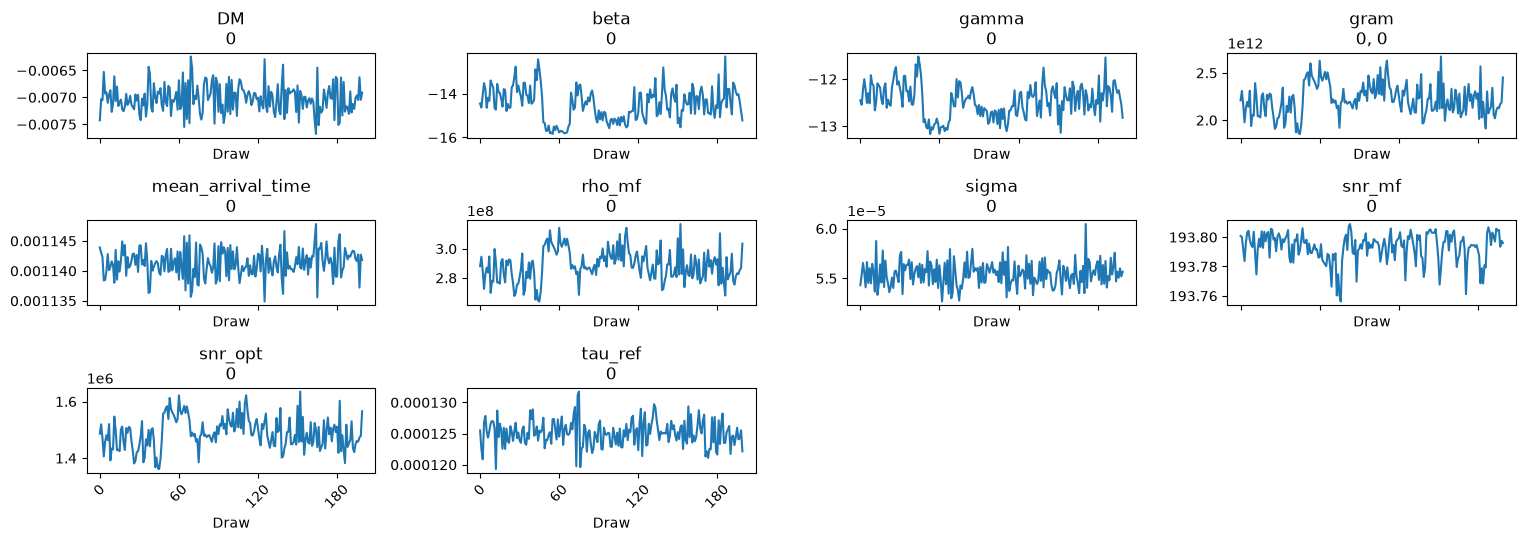

In [233]:
azp.plot_trace(mcmc_data)

# 2. Clean up x-axis tick clutter across all generated subplots
for ax in plt.gcf().axes:
    ax.xaxis.set_major_locator(ticker.MaxNLocator(nbins=4))
    ax.tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

In [234]:
# -------------------------------------------------------------------
# 4. Reconstruct Fluences
# -------------------------------------------------------------------

fluences = draw_fluences_halfnormal_nooverlap_gaussmarg(
    snr_opt=samples["snr_opt"],
    snr_mf=samples["snr_mf"],
    s_opt=s_opt,
    key=key_fluences,
)

## Plot Residual

Plotting for Posterior Draw #23


/tmp/ipykernel_44946/2023688155.py:111: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


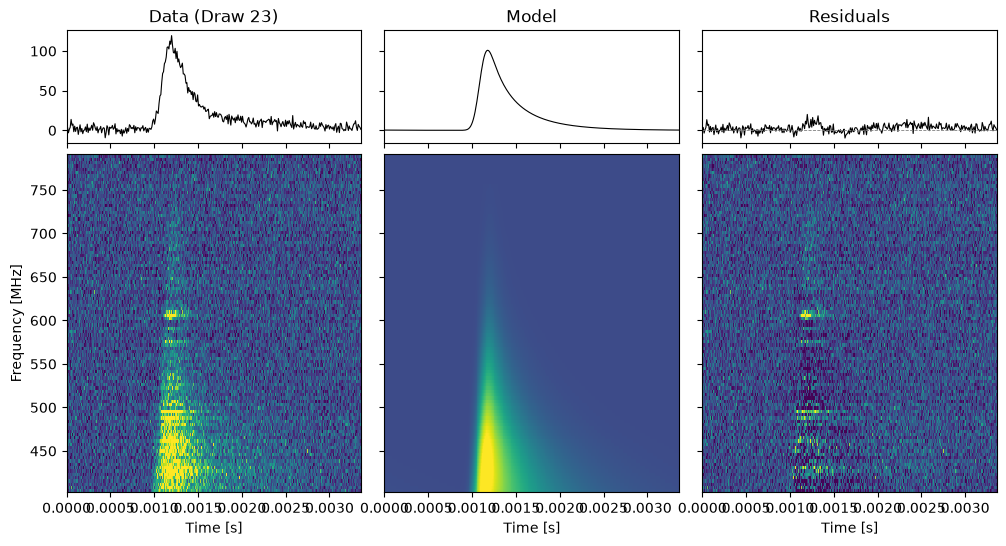

In [235]:
# -------------------------------------------------------------------
# 1. Extract a Random Posterior Draw & Evaluate Forward Model
# -------------------------------------------------------------------
# samples = mcmc.get_samples()
num_draws = len(next(iter(samples.values())))

# Pick a draw index using JAX random
key = jax.random.PRNGKey(0)
draw_idx = int(jax.random.randint(key, shape=(), minval=0, maxval=num_draws))
print(f"Plotting for Posterior Draw #{draw_idx}")

# Extract parameters for the chosen draw directly as JAX scalars
test_params = {
    "mean_arrival_time": samples["mean_arrival_time"][draw_idx],
    "sigma": samples["sigma"][draw_idx],
    "DM": samples["DM"][draw_idx],
    "tau_ref": samples["tau_ref"][draw_idx],
    "gamma": samples["gamma"][draw_idx],
    "beta": samples["beta"][draw_idx],
    "freq_ref": jnp.float32(600.0)
}
A_scale = fluences[draw_idx]

# Extract amplitude scale from posterior ('gram' or fallback to default)
# A_scale = (
#     samples["gram"][draw_idx] if "gram" in samples else fluences[draw_idx]
# )

# Evaluate model in Fourier domain and transform to Time Domain
M_FD = single_pulse_fn(test_params) * A_scale
M_TD = (1.0 / dt) * jnp.fft.irfft(M_FD, n=Nseg, axis=-1)

# Reconstruct baseline-subtracted data in Time Domain
data_TD = (1.0 / dt) * jnp.fft.irfft(data_reshaped_FFT, n=Nseg, axis=-1)

data_TD_plot = data_TD
model_TD_plot = M_TD
time_plot = time_rel
freq_plot = jnp.squeeze(freq)

# -------------------------------------------------------------------
# 2. Residuals & Frequency Collapsed Time Series
# -------------------------------------------------------------------
resid_TD_plot = data_TD_plot - model_TD_plot

# Frequency-summed time series
data_ts = jnp.nansum(data_TD_plot, axis=0)
model_ts = jnp.nansum(model_TD_plot, axis=0)
resid_ts = data_ts - model_ts

# Shared robust color limits using jnp
vmin, vmax = jnp.nanpercentile(data_TD_plot, jnp.array([1.0, 99.0]))

# -------------------------------------------------------------------
# 3. Figure Layout & Plotting
# -------------------------------------------------------------------
fig = plt.figure(figsize=(12, 6))
gs = gridspec.GridSpec(
    2,
    3,
    height_ratios=[1, 3],
    hspace=0.05,
    wspace=0.08,
    figure=fig,
)

ax_ts_data = fig.add_subplot(gs[0, 0])
ax_ts_model = fig.add_subplot(gs[0, 1], sharey=ax_ts_data)
ax_ts_resid = fig.add_subplot(gs[0, 2], sharey=ax_ts_data)

ax_wf_data = fig.add_subplot(gs[1, 0], sharex=ax_ts_data)
ax_wf_model = fig.add_subplot(gs[1, 1], sharex=ax_ts_model, sharey=ax_wf_data)
ax_wf_resid = fig.add_subplot(gs[1, 2], sharex=ax_ts_resid, sharey=ax_wf_data)

# --- Top row: Frequency-summed time series ---
ax_ts_data.plot(time_plot, data_ts, color="k", lw=0.8)
ax_ts_model.plot(time_plot, model_ts, color="k", lw=0.8)
ax_ts_resid.plot(time_plot, resid_ts, color="k", lw=0.8)
ax_ts_resid.axhline(0, color="gray", lw=0.6, ls="--")

# --- Bottom row: Waterfalls ---
imshow_kwargs = dict(
    aspect="auto",
    origin="lower",
    interpolation="nearest",
    cmap="viridis",
    vmin=vmin,
    vmax=vmax,
    extent=(time_plot[0], time_plot[-1], freq_plot[0], freq_plot[-1]),
)

ax_wf_data.imshow(data_TD_plot, **imshow_kwargs)
ax_wf_model.imshow(model_TD_plot, **imshow_kwargs)
ax_wf_resid.imshow(resid_TD_plot, **imshow_kwargs)

# --- Formatting ---
ax_ts_data.set_title(f"Data (Draw {draw_idx})")
ax_ts_model.set_title("Model")
ax_ts_resid.set_title("Residuals")

ax_wf_data.set_xlabel("Time [s]")
ax_wf_model.set_xlabel("Time [s]")
ax_wf_resid.set_xlabel("Time [s]")
ax_wf_data.set_ylabel("Frequency [MHz]")

for ax in (ax_ts_data, ax_ts_model, ax_ts_resid):
    ax.tick_params(labelbottom=False)
for ax in (ax_ts_model, ax_wf_model, ax_ts_resid, ax_wf_resid):
    ax.tick_params(labelleft=False)

plt.tight_layout()
plt.show()

## Test priors

/tmp/ipykernel_3740517/1299604607.py:117: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


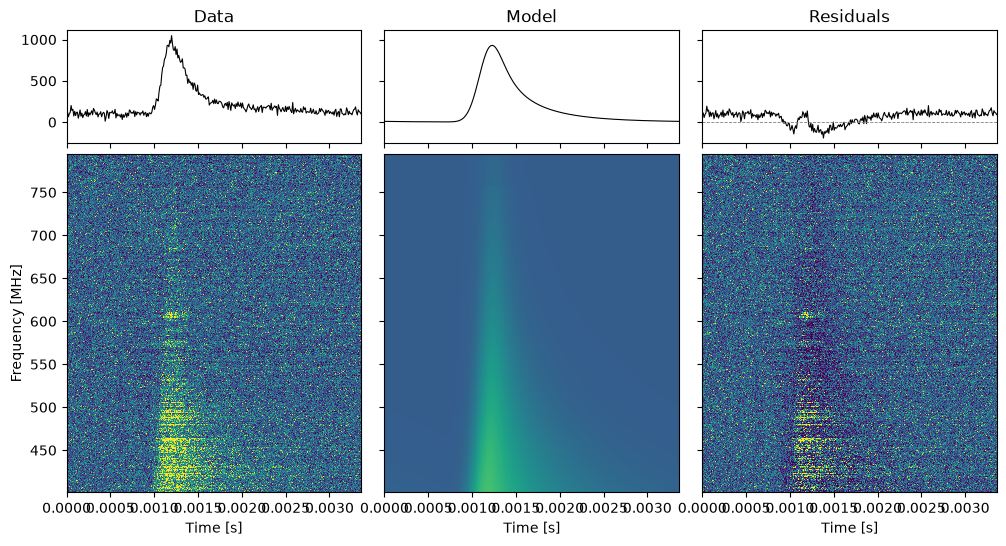

In [26]:

# -------------------------------------------------------------------
# 1. Forward Model Evaluation & IFFT Reconstruction
# -------------------------------------------------------------------
# Set test parameters matching your prior bounds
test_params = {
    "mean_arrival_time": jnp.float32(0.00115),  # (s)
    "sigma": jnp.float32(9.9871264e-05),             # (s)
    "DM": jnp.float32(-0.01),                 # residual DM (pc cm^-3)
    "tau_ref": jnp.float32(0.00017),          # scattering timescale (s)
    "gamma": jnp.float32(-5.6108313),               # spectral index
    "beta": jnp.float32(-2.6474257),                # spectral running
    "freq_ref": jnp.float32(600)
}

# Optional fluence scale (unit-template from setup_model scaled to data level)
A_scale = 4e-4

# Evaluate model in Fourier domain and transform to Time Domain
M_FD = single_pulse_fn(test_params) * A_scale
M_TD = (1.0 / dt) * jnp.fft.irfft(M_FD, n=Nseg, axis=-1)

# Reconstruct baseline-subtracted data in Time Domain
data_TD = (1.0 / dt) * jnp.fft.irfft(data_reshaped_FFT, n=Nseg, axis=-1)

# Convert to NumPy for Matplotlib rendering
data_TD_plot = np.asarray(data_TD)
model_TD_plot = np.asarray(M_TD)
time_plot = np.asarray(time_rel)
freq_plot = np.asarray(freq).squeeze()

# -------------------------------------------------------------------
# 2. Residuals & Frequency Collapsed Time Series
# -------------------------------------------------------------------
resid_TD_plot = data_TD_plot - model_TD_plot

# Frequency-summed time series
data_ts = np.nansum(data_TD_plot, axis=0)
model_ts = np.nansum(model_TD_plot, axis=0)
resid_ts = data_ts - model_ts

# Shared robust color limits
lo_pct, hi_pct = 1, 99
vmin, vmax = np.nanpercentile(data_TD_plot, [lo_pct, hi_pct])

# -------------------------------------------------------------------
# 3. Figure Layout & Plotting
# -------------------------------------------------------------------
fig = plt.figure(figsize=(12, 6))
gs = gridspec.GridSpec(
    2, 3,
    height_ratios=[1, 3],
    hspace=0.05, wspace=0.08,
    figure=fig,
)

ax_ts_data  = fig.add_subplot(gs[0, 0])
ax_ts_model = fig.add_subplot(gs[0, 1], sharey=ax_ts_data)
ax_ts_resid = fig.add_subplot(gs[0, 2], sharey=ax_ts_data)

ax_wf_data  = fig.add_subplot(gs[1, 0], sharex=ax_ts_data)
ax_wf_model = fig.add_subplot(gs[1, 1], sharex=ax_ts_model, sharey=ax_wf_data)
ax_wf_resid = fig.add_subplot(gs[1, 2], sharex=ax_ts_resid, sharey=ax_wf_data)

# --- Top row: Frequency-summed time series ---
ax_ts_data.plot(time_plot, data_ts, color="k", lw=0.8)
ax_ts_model.plot(time_plot, model_ts, color="k", lw=0.8)
ax_ts_resid.plot(time_plot, resid_ts, color="k", lw=0.8)
ax_ts_resid.axhline(0, color="gray", lw=0.6, ls="--")

# --- Bottom row: Waterfalls ---
imshow_kwargs = dict(
    aspect="auto",
    origin="lower",
    interpolation="nearest",
    cmap="viridis",
    vmin=vmin,
    vmax=vmax,
    extent=(time_plot[0], time_plot[-1], freq_plot[0], freq_plot[-1]),
)

ax_wf_data.imshow(data_TD_plot, **imshow_kwargs)
ax_wf_model.imshow(model_TD_plot, **imshow_kwargs)
ax_wf_resid.imshow(resid_TD_plot, **imshow_kwargs)

# --- Formatting ---
ax_ts_data.set_title("Data")
ax_ts_model.set_title("Model")
ax_ts_resid.set_title("Residuals")

ax_wf_data.set_xlabel("Time [s]")
ax_wf_model.set_xlabel("Time [s]")
ax_wf_resid.set_xlabel("Time [s]")
ax_wf_data.set_ylabel("Frequency [MHz]")

for ax in (ax_ts_data, ax_ts_model, ax_ts_resid):
    ax.tick_params(labelbottom=False)
for ax in (ax_ts_model, ax_wf_model, ax_ts_resid, ax_wf_resid):
    ax.tick_params(labelleft=False)

plt.tight_layout()
plt.show()

# Setup orthog SED halfnormal marginalized model and sampler

In [225]:
# -------------------------------------------------------------------
# 2. Model Closure Setup
# -------------------------------------------------------------------
constants_dict = {
    "freq_channels_ref": float(jnp.mean(freq_channels)),
    "delta": -4.0,
    "DM_incoherent": 0.0,
    "channel_width": float(jnp.abs(freq[1] - freq[0])),
}

single_pulse_fn = setup_model(
    constants_dict=constants_dict,
    freqs_channels=freq_channels,
    times=time_rel,
)

# -------------------------------------------------------------------
# 3. Priors & NUTS Sampling
# -------------------------------------------------------------------
# priors = {
#     "mean_arrival_time": dist.Uniform(0.05, 0.06),   # (s) across window
#     "sigma": dist.Uniform(5e-5, 5e-4),               # intrinsic width (s)
#     "DM": dist.Uniform(-0.05, 0.04),                 # residual DM (pc cm^-3)
#     "tau_ref": dist.Uniform(1e-4, 2.5e-4),           # scattering timescale (s)
#     "gamma": dist.Uniform(-8.0, -6.0),               # spectral index
#     "beta": dist.Uniform(-6.0, -4.0),                # spectral running
# }

# test_params = {
#     "mean_arrival_time": jnp.float32(0.00115),  # (s)
#     "sigma": jnp.float32(9.9871264e-05),             # (s)
#     "DM": jnp.float32(-0.01),                 # residual DM (pc cm^-3)
#     "tau_ref": jnp.float32(0.00017),          # scattering timescale (s)
#     "gamma": jnp.float32(-5.6108313),               # spectral index
#     "beta": jnp.float32(-2.6474257),                # spectral running
#     "freq_ref": jnp.float32(600)
# }

priors = {
    # TOA prior: Wide Gaussian centered at 1.15 ms with a 2 ms std dev
    "mean_arrival_time": dist.Uniform(0.00115-.0002, 0.00115+.0002),
    
    "sigma": dist.Uniform(5e-5, 1e-4),              # intrinsic width (s)
    "DM": dist.Uniform(-0.1, 0.1),                  # residual DM (pc cm^-3)
    "tau_ref": dist.Uniform(1e-5, 2e-4),            # scattering timescale (s)
    "gamma": dist.Uniform(-20.0, -2.0),             # spectral index
    "beta": dist.Uniform(-16.0, 1.0),                # spectral running
}
n_pulses = 1
s_opt = 100.0

num_warmup = 1000
num_samples = 200
num_chains = 1

kernel = NUTS(FD_marg_halfnormal_nooverlap_gaussianlikelihood, dense_mass=True)
mcmc = MCMC(kernel, num_warmup=num_warmup, num_samples=num_samples, num_chains=num_chains, 
            chain_method="parallel")

# Fixed master key seed for reproducible sampling across runs
key_sampler, key_fluences = jax.random.split(jax.random.PRNGKey(1))

## Run Marginalized

In [226]:
mcmc.run(
    key_sampler,
    data_fd=data_reshaped_FFT,
    sigma_noise=sigma_noise,
    n_time=Nseg,
    n_pulses=n_pulses,
    priors=priors,
    single_pulse_fn=single_pulse_fn,
    s_opt=s_opt,
    extra_fields=("num_steps","accept_prob","diverging","potential_energy")
)

sample: 100%|██████████| 1200/1200 [00:18<00:00, 64.35it/s, 7 steps of size 4.32e-01. acc. prob=0.90] 


In [227]:
# -------------------------------------------------------------------
# 4. Extract Posteriors
# -------------------------------------------------------------------
samples = mcmc.get_samples()
extra = mcmc.get_extra_fields()

gamma = spectral_coeff_map["gamma_c1"]*samples["c1"] + spectral_coeff_map["gamma_c2"]*samples["c2"] 
beta = spectral_coeff_map["beta_c2"]*samples["c2"]

In [ ]:
gamma = spectral_coeff_map["gamma_c1"]*samples["c1"] + spectral_coeff_map["gamma_c2"]*samples["c2"] 
beta = spectral_coeff_map["beta_c2"]*samples["c2"]

In [228]:
mcmc_data = az.from_numpyro(mcmc, log_likelihood={}, posterior_predictive={})

In [229]:
az.summary(mcmc_data, round_to=3)

/mnt/home/hsiegel/FRBayes/.venv/lib/python3.13/site-packages/arviz_stats/base/diagnostics.py:312: RuntimeWarning: overflow encountered in power
  varvar = ((sims_c**4).mean() - evar**2) / ess
/mnt/home/hsiegel/FRBayes/.venv/lib/python3.13/site-packages/arviz_stats/base/diagnostics.py:312: RuntimeWarning: overflow encountered in scalar power
  varvar = ((sims_c**4).mean() - evar**2) / ess
/mnt/home/hsiegel/FRBayes/.venv/lib/python3.13/site-packages/arviz_stats/base/diagnostics.py:312: RuntimeWarning: invalid value encountered in scalar subtract
  varvar = ((sims_c**4).mean() - evar**2) / ess


,mean,sd,eti89_lb,eti89_ub,ess_bulk,ess_tail,r_hat,mcse_mean,mcse_sd
DM[0],-7.000000e-03,0.000000e+00,-7.000000e-03,-7.000000e-03,275.683,158.939,NaN,0.000000e+00,0.000
beta[0],-1.449200e+01,7.400000e-01,-1.569500e+01,-1.341600e+01,25.333,14.884,NaN,1.430000e-01,0.079
gamma[0],-1.247000e+01,3.430000e-01,-1.302400e+01,-1.193500e+01,27.344,25.573,NaN,6.500000e-02,0.037
"gram[0, 0]",2.220921e+12,1.640928e+11,1.965181e+12,2.488307e+12,35.975,53.172,NaN,2.806642e+10,NaN
mean_arrival_time[0],1.000000e-03,0.000000e+00,1.000000e-03,1.000000e-03,296.481,167.923,NaN,0.000000e+00,0.000
rho_mf[0],2.886088e+08,1.064327e+07,2.716591e+08,3.056869e+08,36.080,53.172,NaN,1.812656e+06,903361.102
sigma[0],0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,271.178,181.440,NaN,0.000000e+00,0.000
snr_mf[0],1.937930e+02,1.000000e-02,1.937740e+02,1.938050e+02,70.439,92.515,NaN,1.000000e-03,0.001
snr_opt[0],1.489263e+06,5.492778e+04,1.401849e+06,1.577436e+06,35.975,53.172,NaN,9.358927e+03,4664.117
tau_ref[0],0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,189.399,94.371,NaN,0.000000e+00,0.000


In [230]:
jnp.corrcoef(samples["gamma"][:,0], samples["beta"][:,0])[0,1]

Array(0.9809228, dtype=float32)

In [231]:
ex = mcmc.get_extra_fields()
ns = jnp.array(ex["num_steps"])
print(f"gradients/sample: mean {ns.mean():.1f}  median {jnp.median(ns)}  max {ns.max()}")
print(f"at max tree depth: {100*jnp.mean(ns >= 2**10 - 1):.1f}%")   # adjust if max_tree_depth != 10
print(f"accept_prob: mean {jnp.array(ex['accept_prob']).mean():.3f}")
print(f"divergences: {int(jnp.array(ex['diverging']).sum())} / {len(ns)}")
print(f"step size: {float(mcmc.last_state.adapt_state.step_size):.3e}")
print(f"potential_energy: mean {jnp.array(ex['potential_energy']).mean():.1f}  sd {jnp.array(ex['potential_energy']).std():.2f}")

gradients/sample: mean 8.0  median 7.0  max 31
at max tree depth: 0.0%
accept_prob: mean 0.899
divergences: 0 / 200
step size: 4.318e-01
potential_energy: mean -18761.4  sd 2.11


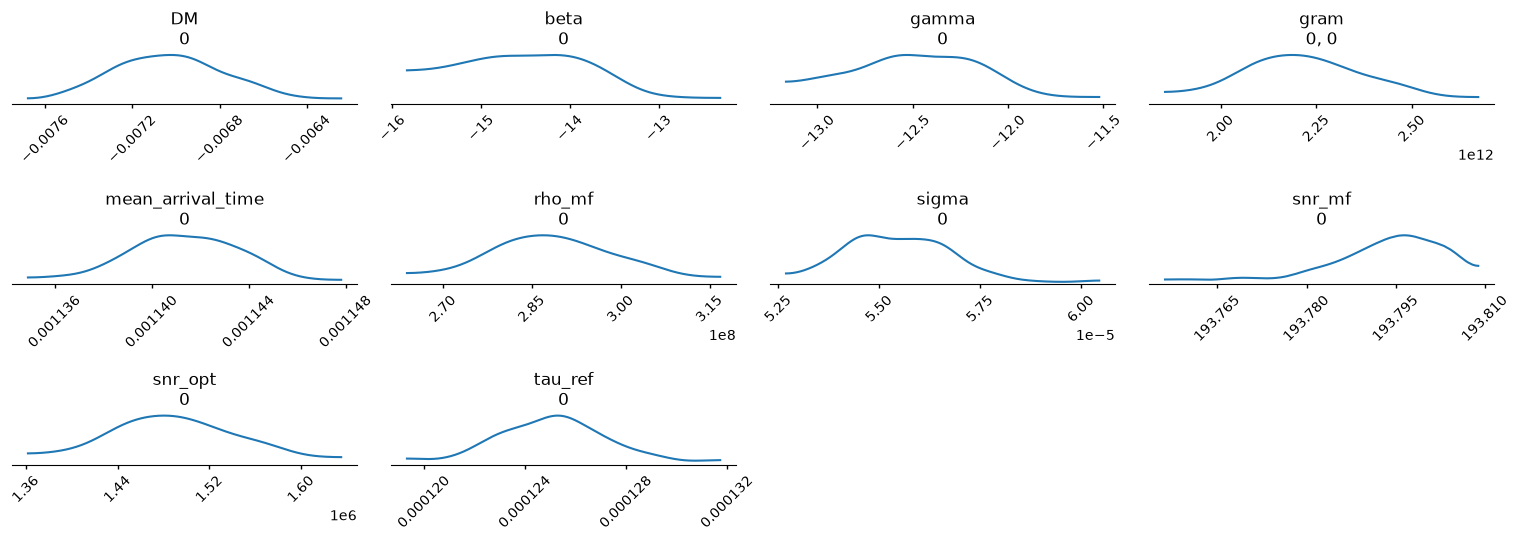

In [232]:
axes = azp.plot_dist(mcmc_data, stats=None)
for ax in plt.gcf().axes:
    ax.xaxis.set_major_locator(ticker.MaxNLocator(nbins=4))  # Limit to 4 ticks max
    ax.tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.subplots_adjust(wspace=0.1)
plt.subplots_adjust(hspace=2.5)

# Remove all "mean" text annotations across all subplots
for ax in plt.gcf().axes:
    for text in list(ax.texts):
        if "mean" in text.get_text():
            text.remove()
            # Remove horizontal interval lines (they only have 2 x-data points)
    for line in list(ax.lines):
        if len(line.get_xdata()) <= 2:
            line.remove()
            # 3. Remove point estimate dots
    for collection in list(ax.collections):
        collection.remove()

plt.draw()

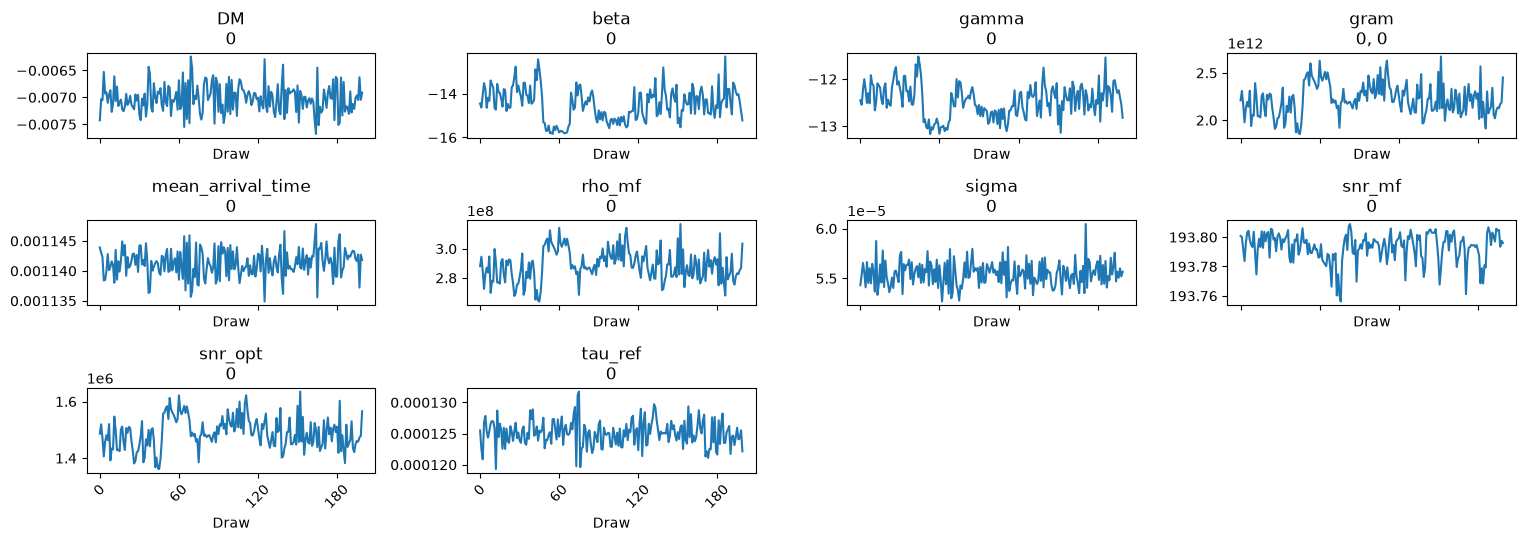

In [233]:
azp.plot_trace(mcmc_data)

# 2. Clean up x-axis tick clutter across all generated subplots
for ax in plt.gcf().axes:
    ax.xaxis.set_major_locator(ticker.MaxNLocator(nbins=4))
    ax.tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

In [234]:
# -------------------------------------------------------------------
# 4. Reconstruct Fluences
# -------------------------------------------------------------------

fluences = draw_fluences_halfnormal_nooverlap_gaussmarg(
    snr_opt=samples["snr_opt"],
    snr_mf=samples["snr_mf"],
    s_opt=s_opt,
    key=key_fluences,
)

## Plot Residual

Plotting for Posterior Draw #23


/tmp/ipykernel_44946/2023688155.py:111: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


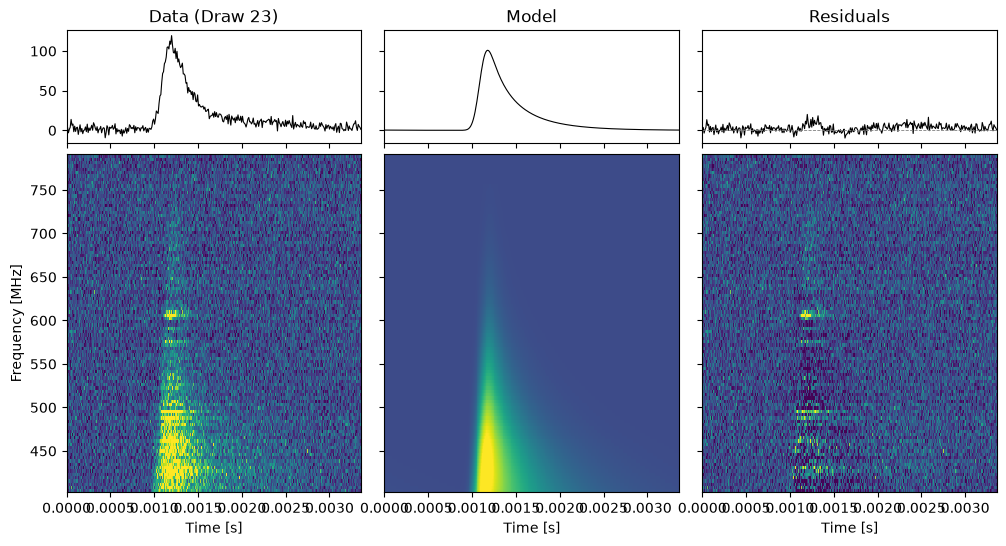

In [235]:
# -------------------------------------------------------------------
# 1. Extract a Random Posterior Draw & Evaluate Forward Model
# -------------------------------------------------------------------
# samples = mcmc.get_samples()
num_draws = len(next(iter(samples.values())))

# Pick a draw index using JAX random
key = jax.random.PRNGKey(0)
draw_idx = int(jax.random.randint(key, shape=(), minval=0, maxval=num_draws))
print(f"Plotting for Posterior Draw #{draw_idx}")

# Extract parameters for the chosen draw directly as JAX scalars
test_params = {
    "mean_arrival_time": samples["mean_arrival_time"][draw_idx],
    "sigma": samples["sigma"][draw_idx],
    "DM": samples["DM"][draw_idx],
    "tau_ref": samples["tau_ref"][draw_idx],
    "gamma": samples["gamma"][draw_idx],
    "beta": samples["beta"][draw_idx],
    "freq_ref": jnp.float32(600.0)
}
A_scale = fluences[draw_idx]

# Extract amplitude scale from posterior ('gram' or fallback to default)
# A_scale = (
#     samples["gram"][draw_idx] if "gram" in samples else fluences[draw_idx]
# )

# Evaluate model in Fourier domain and transform to Time Domain
M_FD = single_pulse_fn(test_params) * A_scale
M_TD = (1.0 / dt) * jnp.fft.irfft(M_FD, n=Nseg, axis=-1)

# Reconstruct baseline-subtracted data in Time Domain
data_TD = (1.0 / dt) * jnp.fft.irfft(data_reshaped_FFT, n=Nseg, axis=-1)

data_TD_plot = data_TD
model_TD_plot = M_TD
time_plot = time_rel
freq_plot = jnp.squeeze(freq)

# -------------------------------------------------------------------
# 2. Residuals & Frequency Collapsed Time Series
# -------------------------------------------------------------------
resid_TD_plot = data_TD_plot - model_TD_plot

# Frequency-summed time series
data_ts = jnp.nansum(data_TD_plot, axis=0)
model_ts = jnp.nansum(model_TD_plot, axis=0)
resid_ts = data_ts - model_ts

# Shared robust color limits using jnp
vmin, vmax = jnp.nanpercentile(data_TD_plot, jnp.array([1.0, 99.0]))

# -------------------------------------------------------------------
# 3. Figure Layout & Plotting
# -------------------------------------------------------------------
fig = plt.figure(figsize=(12, 6))
gs = gridspec.GridSpec(
    2,
    3,
    height_ratios=[1, 3],
    hspace=0.05,
    wspace=0.08,
    figure=fig,
)

ax_ts_data = fig.add_subplot(gs[0, 0])
ax_ts_model = fig.add_subplot(gs[0, 1], sharey=ax_ts_data)
ax_ts_resid = fig.add_subplot(gs[0, 2], sharey=ax_ts_data)

ax_wf_data = fig.add_subplot(gs[1, 0], sharex=ax_ts_data)
ax_wf_model = fig.add_subplot(gs[1, 1], sharex=ax_ts_model, sharey=ax_wf_data)
ax_wf_resid = fig.add_subplot(gs[1, 2], sharex=ax_ts_resid, sharey=ax_wf_data)

# --- Top row: Frequency-summed time series ---
ax_ts_data.plot(time_plot, data_ts, color="k", lw=0.8)
ax_ts_model.plot(time_plot, model_ts, color="k", lw=0.8)
ax_ts_resid.plot(time_plot, resid_ts, color="k", lw=0.8)
ax_ts_resid.axhline(0, color="gray", lw=0.6, ls="--")

# --- Bottom row: Waterfalls ---
imshow_kwargs = dict(
    aspect="auto",
    origin="lower",
    interpolation="nearest",
    cmap="viridis",
    vmin=vmin,
    vmax=vmax,
    extent=(time_plot[0], time_plot[-1], freq_plot[0], freq_plot[-1]),
)

ax_wf_data.imshow(data_TD_plot, **imshow_kwargs)
ax_wf_model.imshow(model_TD_plot, **imshow_kwargs)
ax_wf_resid.imshow(resid_TD_plot, **imshow_kwargs)

# --- Formatting ---
ax_ts_data.set_title(f"Data (Draw {draw_idx})")
ax_ts_model.set_title("Model")
ax_ts_resid.set_title("Residuals")

ax_wf_data.set_xlabel("Time [s]")
ax_wf_model.set_xlabel("Time [s]")
ax_wf_resid.set_xlabel("Time [s]")
ax_wf_data.set_ylabel("Frequency [MHz]")

for ax in (ax_ts_data, ax_ts_model, ax_ts_resid):
    ax.tick_params(labelbottom=False)
for ax in (ax_ts_model, ax_wf_model, ax_ts_resid, ax_wf_resid):
    ax.tick_params(labelleft=False)

plt.tight_layout()
plt.show()

## Test priors

/tmp/ipykernel_3740517/1299604607.py:117: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


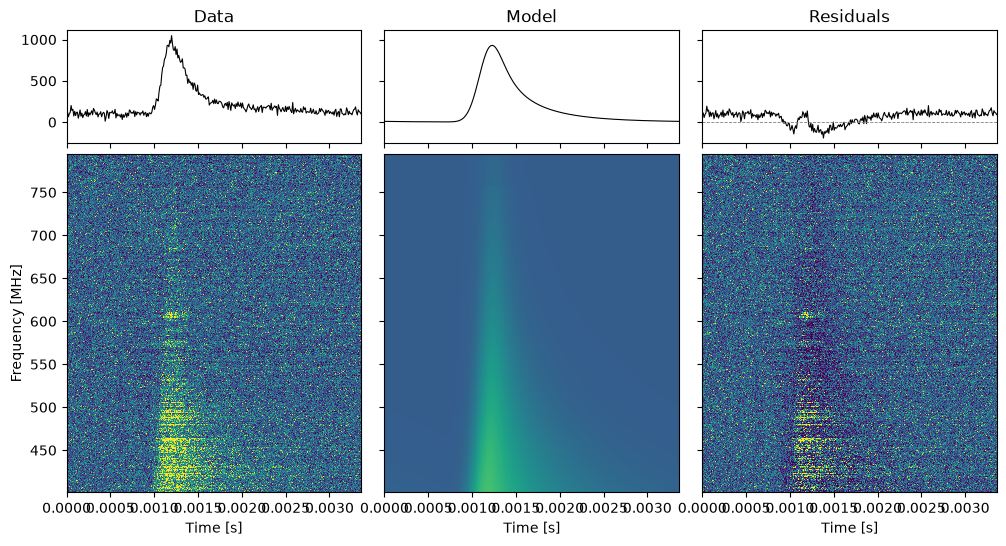

In [26]:

# -------------------------------------------------------------------
# 1. Forward Model Evaluation & IFFT Reconstruction
# -------------------------------------------------------------------
# Set test parameters matching your prior bounds
test_params = {
    "mean_arrival_time": jnp.float32(0.00115),  # (s)
    "sigma": jnp.float32(9.9871264e-05),             # (s)
    "DM": jnp.float32(-0.01),                 # residual DM (pc cm^-3)
    "tau_ref": jnp.float32(0.00017),          # scattering timescale (s)
    "gamma": jnp.float32(-5.6108313),               # spectral index
    "beta": jnp.float32(-2.6474257),                # spectral running
    "freq_ref": jnp.float32(600)
}

# Optional fluence scale (unit-template from setup_model scaled to data level)
A_scale = 4e-4

# Evaluate model in Fourier domain and transform to Time Domain
M_FD = single_pulse_fn(test_params) * A_scale
M_TD = (1.0 / dt) * jnp.fft.irfft(M_FD, n=Nseg, axis=-1)

# Reconstruct baseline-subtracted data in Time Domain
data_TD = (1.0 / dt) * jnp.fft.irfft(data_reshaped_FFT, n=Nseg, axis=-1)

# Convert to NumPy for Matplotlib rendering
data_TD_plot = np.asarray(data_TD)
model_TD_plot = np.asarray(M_TD)
time_plot = np.asarray(time_rel)
freq_plot = np.asarray(freq).squeeze()

# -------------------------------------------------------------------
# 2. Residuals & Frequency Collapsed Time Series
# -------------------------------------------------------------------
resid_TD_plot = data_TD_plot - model_TD_plot

# Frequency-summed time series
data_ts = np.nansum(data_TD_plot, axis=0)
model_ts = np.nansum(model_TD_plot, axis=0)
resid_ts = data_ts - model_ts

# Shared robust color limits
lo_pct, hi_pct = 1, 99
vmin, vmax = np.nanpercentile(data_TD_plot, [lo_pct, hi_pct])

# -------------------------------------------------------------------
# 3. Figure Layout & Plotting
# -------------------------------------------------------------------
fig = plt.figure(figsize=(12, 6))
gs = gridspec.GridSpec(
    2, 3,
    height_ratios=[1, 3],
    hspace=0.05, wspace=0.08,
    figure=fig,
)

ax_ts_data  = fig.add_subplot(gs[0, 0])
ax_ts_model = fig.add_subplot(gs[0, 1], sharey=ax_ts_data)
ax_ts_resid = fig.add_subplot(gs[0, 2], sharey=ax_ts_data)

ax_wf_data  = fig.add_subplot(gs[1, 0], sharex=ax_ts_data)
ax_wf_model = fig.add_subplot(gs[1, 1], sharex=ax_ts_model, sharey=ax_wf_data)
ax_wf_resid = fig.add_subplot(gs[1, 2], sharex=ax_ts_resid, sharey=ax_wf_data)

# --- Top row: Frequency-summed time series ---
ax_ts_data.plot(time_plot, data_ts, color="k", lw=0.8)
ax_ts_model.plot(time_plot, model_ts, color="k", lw=0.8)
ax_ts_resid.plot(time_plot, resid_ts, color="k", lw=0.8)
ax_ts_resid.axhline(0, color="gray", lw=0.6, ls="--")

# --- Bottom row: Waterfalls ---
imshow_kwargs = dict(
    aspect="auto",
    origin="lower",
    interpolation="nearest",
    cmap="viridis",
    vmin=vmin,
    vmax=vmax,
    extent=(time_plot[0], time_plot[-1], freq_plot[0], freq_plot[-1]),
)

ax_wf_data.imshow(data_TD_plot, **imshow_kwargs)
ax_wf_model.imshow(model_TD_plot, **imshow_kwargs)
ax_wf_resid.imshow(resid_TD_plot, **imshow_kwargs)

# --- Formatting ---
ax_ts_data.set_title("Data")
ax_ts_model.set_title("Model")
ax_ts_resid.set_title("Residuals")

ax_wf_data.set_xlabel("Time [s]")
ax_wf_model.set_xlabel("Time [s]")
ax_wf_resid.set_xlabel("Time [s]")
ax_wf_data.set_ylabel("Frequency [MHz]")

for ax in (ax_ts_data, ax_ts_model, ax_ts_resid):
    ax.tick_params(labelbottom=False)
for ax in (ax_ts_model, ax_wf_model, ax_ts_resid, ax_wf_resid):
    ax.tick_params(labelleft=False)

plt.tight_layout()
plt.show()